[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MrOpinions/FDS-Lab-Manual/blob/main/FDS_Lab_All_Experiments.ipynb)

# CS23334 – Fundamentals of Data Science Lab
### All 20 experiments in one notebook

**Run everything:** *Runtime → Run all*.  
**Run one experiment:** use the **table of contents** (left sidebar, ☰ icon) to jump to it, then run only the cells under that heading. Every experiment is self-contained (it imports its own libraries and creates or loads its own data), so any section can be run on its own, in any order.

**About the datasets:** where the lab manual uses a CSV file that isn't shared, the notebook creates a sample dataset automatically. If you have the real file, upload it to Colab's file panel (📁 on the left) using the same file name *before* running, and it will be used instead.

**Experiments**

1. Data Science Job Trends, Roles, Data Types and Encryption
2. CSV Upload, Preprocessing and Visualization
3. Data Visualization: Line Plot, Bar Chart and Pie Chart
4. Word Frequency in a Body of Text
5. Data Collection and Initial Exploration (Diabetes Dataset)
6. Time Series Analysis of Website Traffic
7. Random Sampling and Sampling Distribution
8. Z-Test in Python
9. Matplotlib / Seaborn Visualization on the Iris Data Set
10. NumPy Array Functions
11. Pandas Library Use Cases
12. Outlier Detection (IQR Method)
13. Handling Missing Values and Inappropriate Data
14. Feature Scaling
15. Data Preprocessing
16. EDA – Quantitative and Qualitative Analysis
17. Linear Regression
18. K-Nearest Neighbours (KNN) Algorithm
19. Logistic Regression
20. K-Means Clustering

---
## Experiment 1: Data Science Job Trends, Roles, Data Types and Encryption

**Aim:** To visualise data science job trends and role distribution, differentiate structured / semi-structured / unstructured data, and encrypt & decrypt sensitive data.

### 1.a Trend of data science job postings over the last decade

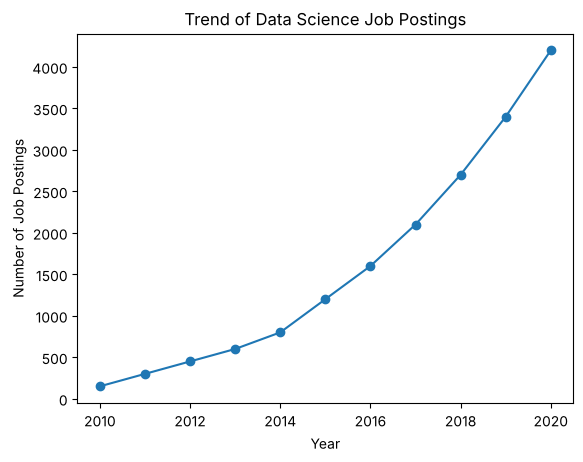

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

data = {'Year': list(range(2010, 2021)),
        'Job Postings': [150, 300, 450, 600, 800, 1200, 1600, 2100, 2700, 3400, 4200]}

df = pd.DataFrame(data)
plt.plot(df['Year'], df['Job Postings'], marker='o')
plt.title('Trend of Data Science Job Postings')
plt.xlabel('Year')
plt.ylabel('Number of Job Postings')
plt.show()

### 1.b Distribution of data science roles

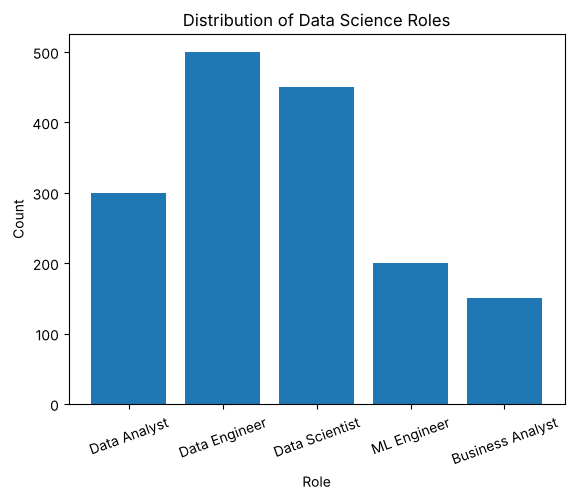

In [2]:
import matplotlib.pyplot as plt

roles = ['Data Analyst', 'Data Engineer', 'Data Scientist', 'ML Engineer', 'Business Analyst']
counts = [300, 500, 450, 200, 150]
plt.bar(roles, counts)
plt.title('Distribution of Data Science Roles')
plt.xlabel('Role')
plt.ylabel('Count')
plt.xticks(rotation=20)
plt.show()

### 1.c Structured, unstructured and semi-structured data

In [3]:
import pandas as pd

# Structured data example
structured_data = pd.DataFrame({
    'ID': [1, 2, 3],
    'Name': ['Alice', 'Bob', 'Charlie'],
    'Age': [25, 30, 35]
})
print("Structured Data:\n", structured_data)

# Unstructured data example
unstructured_data = "This is an example of unstructured data. It can be a piece of text, an image, or a video file."
print("\nUnstructured Data:\n", unstructured_data)

# Semi-structured data example (JSON)
semi_structured_data = {'ID': 1, 'Name': 'Alice', 'Attributes': {'Height': 165, 'Weight': 68}}
print("\nSemi-structured Data:\n", semi_structured_data)

Structured Data:
    ID     Name  Age
0   1    Alice   25
1   2      Bob   30
2   3  Charlie   35

Unstructured Data:
 This is an example of unstructured data. It can be a piece of text, an image, or a video file.

Semi-structured Data:
 {'ID': 1, 'Name': 'Alice', 'Attributes': {'Height': 165, 'Weight': 68}}


### 1.d Encrypt and decrypt sensitive data

In [4]:
from cryptography.fernet import Fernet

# Generate key and encrypt data
key = Fernet.generate_key()
cipher_suite = Fernet(key)
plain_text = b"Rajalakshmi Engineering College."
cipher_text = cipher_suite.encrypt(plain_text)

# Decrypt data
decrypted_text = cipher_suite.decrypt(cipher_text)
print("Original Data:", plain_text)
print("Encrypted Data:", cipher_text)
print("Decrypted Data:", decrypted_text)

Original Data: b'Rajalakshmi Engineering College.'
Encrypted Data: b'gAAAAABq3jAZcTO9DjkdI-1Ou2DaT1qAwKTwmDL9VN97mEf7kaiDhjebN0_FB3r1k3-1R1Wf3cINp06se-bdvrkN89p6OVL2AD38qiZ1QpyPHccwqTiSUgWeRPN4gHZWUUBEcIZ0fE41'
Decrypted Data: b'Rajalakshmi Engineering College.'


---
## Experiment 2: CSV Upload, Preprocessing and Visualization

**Aim:** To load a CSV data set (sales_data.csv), preprocess it and visualise it.

**Data:** if `sales_data.csv` is not already in Colab, the next cell creates a 16-row sample sales file.

In [5]:
import os, pandas as pd

if not os.path.exists('sales_data.csv'):
    rows = [  # Date, Product, Sales, Quantity, Region
        ('Product A', 200, 4, 'North'), ('Product B', 150, 3, 'South'), ('Product A', 220, 5, 'North'),
        ('Product C', 300, 6, 'East'),  ('Product B', 180, 4, 'West'),  ('Product A', 240, 6, 'North'),
        ('Product C', 320, 7, 'East'),  ('Product B', 160, 3, 'South'), ('Product A', 250, 6, 'North'),
        ('Product C', 340, 8, 'East'),  ('Product B', 170, 4, 'South'), ('Product A', 220, 6, 'North'),
        ('Product C', 320, 7, 'East'),  ('Product B', 190, 3, 'West'),  ('Product A', 220, 6, 'North'),
        ('Product C', 320, 8, 'East'),
    ]
    sample = pd.DataFrame(rows, columns=['Product', 'Sales', 'Quantity', 'Region'])
    sample.insert(0, 'Date', pd.date_range('2023-01-01', periods=len(sample)).strftime('%Y-%m-%d'))
    sample.to_csv('sales_data.csv', index=False)
    print("Created sample sales_data.csv")
else:
    print("Using your uploaded sales_data.csv")

Created sample sales_data.csv


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the data into a pandas DataFrame
file_path = 'sales_data.csv'
df = pd.read_csv(file_path)

# Display the first few rows of the DataFrame
print(df.head())

# Check for missing values
print(df.isnull().sum())

# Fill or drop missing values if necessary
df['Sales'] = df['Sales'].fillna(df['Sales'].mean())
df.dropna(subset=['Product', 'Quantity', 'Region'], inplace=True)

# Summary statistics
print(df.describe())

# Group by product and calculate the total sales and quantity
product_summary = df.groupby('Product').agg({'Sales': 'sum', 'Quantity': 'sum'}).reset_index()
print(product_summary)

         Date    Product  Sales  Quantity Region
0  2023-01-01  Product A    200         4  North
1  2023-01-02  Product B    150         3  South
2  2023-01-03  Product A    220         5  North
3  2023-01-04  Product C    300         6   East
4  2023-01-05  Product B    180         4   West
Date        0
Product     0
Sales       0
Quantity    0
Region      0
dtype: int64
            Sales   Quantity
count   16.000000  16.000000
mean   237.500000   5.375000
std     63.822671   1.707825
min    150.000000   3.000000
25%    187.500000   4.000000
50%    220.000000   6.000000
75%    305.000000   6.250000
max    340.000000   8.000000
     Product  Sales  Quantity
0  Product A   1350        33
1  Product B    850        17
2  Product C   1600        36


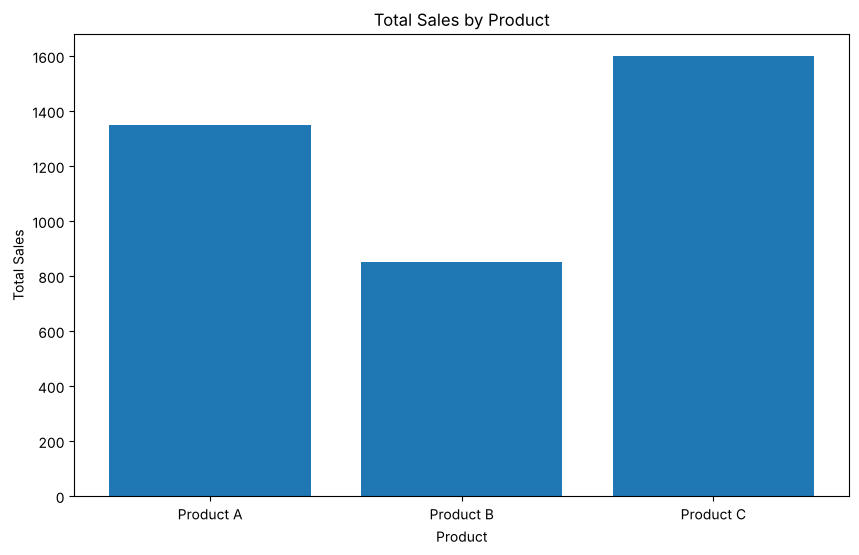

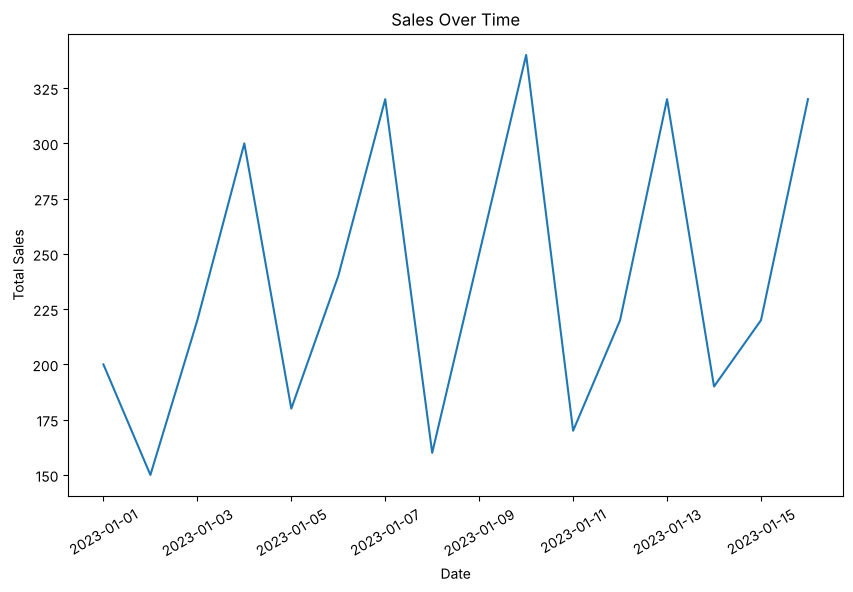

In [7]:
# Bar plot of total sales by product
plt.figure(figsize=(10, 6))
plt.bar(product_summary['Product'], product_summary['Sales'])
plt.xlabel('Product')
plt.ylabel('Total Sales')
plt.title('Total Sales by Product')
plt.show()

# Line plot of sales over time
df['Date'] = pd.to_datetime(df['Date'])
sales_over_time = df.groupby('Date').agg({'Sales': 'sum'}).reset_index()
plt.figure(figsize=(10, 6))
plt.plot(sales_over_time['Date'], sales_over_time['Sales'])
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.title('Sales Over Time')
plt.xticks(rotation=30)
plt.show()

Product  Product A  Product B  Product C
Region                                  
East             0          0       1600
North         1350          0          0
South            0        480          0
West             0        370          0
             Sales  Quantity
Sales     1.000000  0.926623
Quantity  0.926623  1.000000


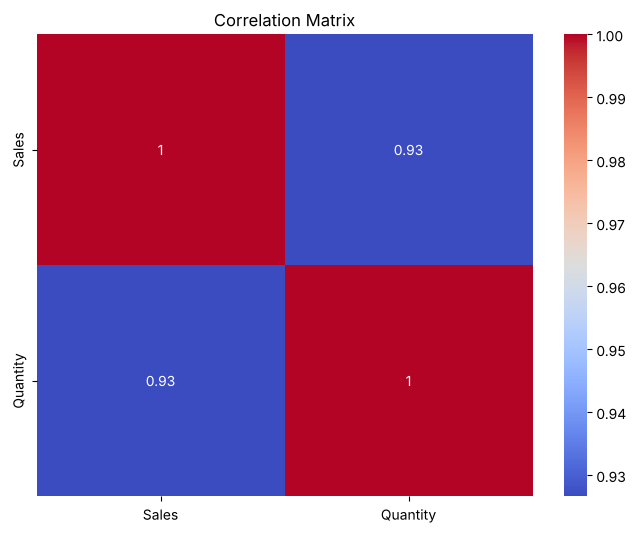

In [8]:
# Pivot table to analyze sales by region and product
pivot_table = df.pivot_table(values='Sales', index='Region', columns='Product', aggfunc='sum', fill_value=0)
print(pivot_table)

# Correlation matrix (numeric columns only)
correlation_matrix = df.corr(numeric_only=True)
print(correlation_matrix)

# Heatmap of the correlation matrix
import seaborn as sns
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

---
## Experiment 3: Data Visualization: Line Plot, Bar Chart and Pie Chart

**Aim:** To show data visualization using a line plot, a bar chart and a pie chart.

### 3.a Line plot

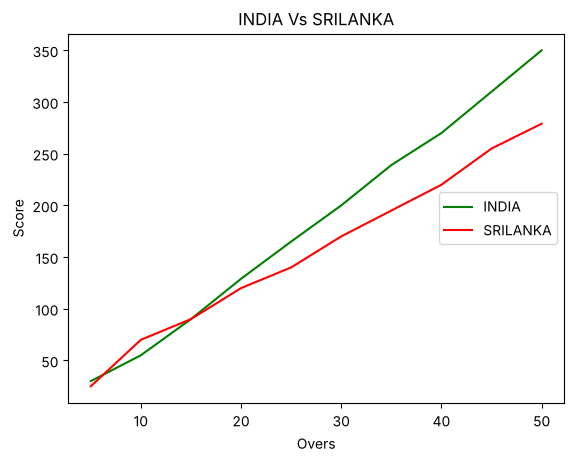

In [9]:
import matplotlib.pyplot as cricket

Overs = list(range(5, 51, 5))
Indian_Score = [30, 55, 90, 129, 165, 200, 239, 270, 310, 350]
Srilankan_Score = [25, 70, 90, 120, 140, 170, 195, 220, 255, 279]

cricket.plot(Overs, Indian_Score, color="green", label="INDIA")
cricket.plot(Overs, Srilankan_Score, color="red", label="SRILANKA")
cricket.title("INDIA Vs SRILANKA")
cricket.xlabel("Overs")
cricket.ylabel("Score")
cricket.legend(loc="center right")
cricket.show()

### 3.b Bar chart

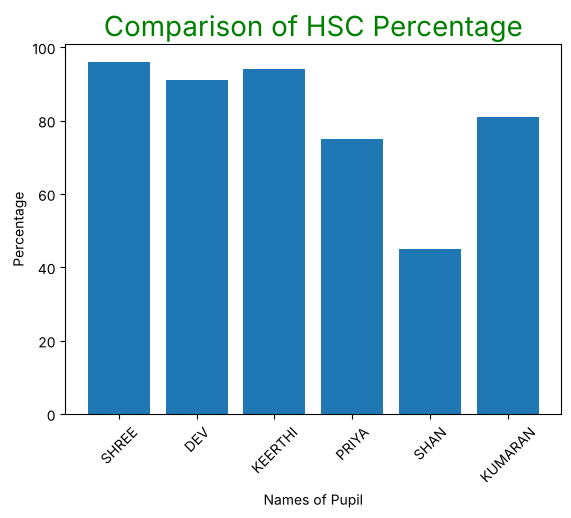

In [10]:
import matplotlib.pyplot as hscmark
import numpy as np

Names = ['SHREE', 'DEV', 'KEERTHI', 'PRIYA', 'SHAN', 'KUMARAN']
xaxis = np.arange(len(Names))
Percentage_hsc = [96, 91, 94, 75, 45, 81]
hscmark.bar(Names, Percentage_hsc)
hscmark.xticks(xaxis, Names, rotation=45)
hscmark.xlabel("Names of Pupil")
hscmark.ylabel("Percentage")
hscmark.title("Comparison of HSC Percentage", fontsize=20, color="green")
hscmark.show()

### 3.c Pie chart

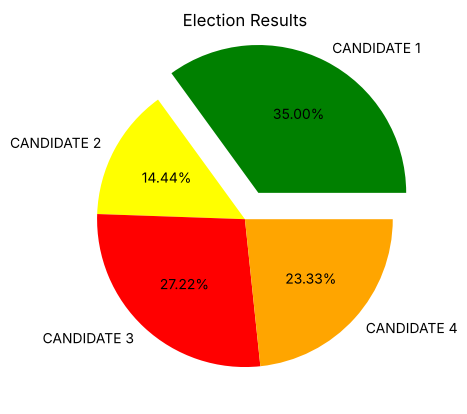

In [11]:
import matplotlib.pyplot as election

# Election data
labels = ['CANDIDATE 1', 'CANDIDATE 2', 'CANDIDATE 3', 'CANDIDATE 4']
Votes = [315, 130, 245, 210]
colors = ['green', 'yellow', 'red', 'orange']
explode = (0.2, 0, 0, 0)

# Plotting the pie chart
election.pie(Votes, labels=labels, colors=colors, explode=explode, autopct='%0.2f%%')
election.title('Election Results')
election.show()

---
## Experiment 4: Word Frequency in a Body of Text

**Aim:** To count the frequency of occurrence of words in a body of text (text processing with NLTK).

In [12]:
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import gutenberg

# Download the gutenberg corpus and tokenizer models
nltk.download('gutenberg')
nltk.download('punkt')
nltk.download('punkt_tab')   # needed by newer NLTK versions

# Load the text from the gutenberg corpus
sample = gutenberg.raw("austen-emma.txt")

# Tokenize the sample text
token = word_tokenize(sample)

# Create a list of the first 50 tokens
wlist = []
for i in range(50):
    wlist.append(token[i])

# Calculate the frequency of each word in the list
wordfreq = [wlist.count(w) for w in wlist]

# Print the word-frequency pairs
print("Pairs\n" + str(list(zip(wlist, wordfreq))))

[nltk_data] Downloading package gutenberg to /root/nltk_data...


[nltk_data]   Unzipping corpora/gutenberg.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...


[nltk_data]   Unzipping tokenizers/punkt.zip.


[nltk_data] Downloading package punkt_tab to /root/nltk_data...


[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Pairs
[('[', 1), ('Emma', 2), ('by', 1), ('Jane', 1), ('Austen', 1), ('1816', 1), (']', 1), ('VOLUME', 1), ('I', 2), ('CHAPTER', 1), ('I', 2), ('Emma', 2), ('Woodhouse', 1), (',', 5), ('handsome', 1), (',', 5), ('clever', 1), (',', 5), ('and', 3), ('rich', 1), (',', 5), ('with', 2), ('a', 1), ('comfortable', 1), ('home', 1), ('and', 3), ('happy', 1), ('disposition', 1), (',', 5), ('seemed', 1), ('to', 1), ('unite', 1), ('some', 1), ('of', 2), ('the', 2), ('best', 1), ('blessings', 1), ('of', 2), ('existence', 1), (';', 1), ('and', 3), ('had', 1), ('lived', 1), ('nearly', 1), ('twenty-one', 1), ('years', 1), ('in', 1), ('the', 2), ('world', 1), ('with', 2)]


**Extra:** most common words in the whole book.

In [13]:
from nltk import FreqDist
words = [w.lower() for w in token if w.isalpha()]
FreqDist(words).most_common(10)

[('the', 5201),
 ('to', 5181),
 ('and', 4877),
 ('of', 4284),
 ('i', 3177),
 ('a', 3124),
 ('it', 2503),
 ('her', 2448),
 ('was', 2396),
 ('she', 2336)]

---
## Experiment 5: Data Collection and Initial Exploration (Diabetes Dataset)

**Aim:** To collect, load and perform initial exploration of the diabetes dataset.

**Data:** the cell below downloads the Pima Indians diabetes data set. If `diabetes.csv` is already uploaded to Colab it uses that; if there is no internet, it creates a sample with the same columns.

In [14]:
import os
import numpy as np
import pandas as pd

cols = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
        'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

if not os.path.exists('diabetes.csv'):
    try:
        pd.read_csv("https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv").to_csv('diabetes.csv', index=False)
        print("Downloaded diabetes.csv")
    except Exception as e:
        print("Download failed (", type(e).__name__, ") - creating a sample data set instead")
        rng = np.random.default_rng(0)
        n = 768
        sample = pd.DataFrame({
            'Pregnancies': rng.poisson(3.8, n).clip(0, 17),
            'Glucose': rng.normal(121, 32, n).clip(0, 199).round(),
            'BloodPressure': rng.normal(69, 19, n).clip(0, 122).round(),
            'SkinThickness': rng.normal(20, 16, n).clip(0, 99).round(),
            'Insulin': rng.gamma(1.2, 70, n).clip(0, 846).round(),
            'BMI': rng.normal(32, 7.9, n).clip(0, 67).round(1),
            'DiabetesPedigreeFunction': rng.gamma(2, 0.24, n).clip(0.08, 2.42).round(3),
            'Age': (21 + rng.gamma(2, 6, n)).clip(21, 81).round(),
            'Outcome': (rng.random(n) < 0.35).astype(int)})
        sample.to_csv('diabetes.csv', index=False)
else:
    print("Using your uploaded diabetes.csv")

Downloaded diabetes.csv


#### 1. Data Collection

In [15]:
import pandas as pd

# Load the dataset
diabetes_df = pd.read_csv("diabetes.csv")

# Display the first few rows
print(diabetes_df.head())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


#### 2. Initial Exploration

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
None
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578

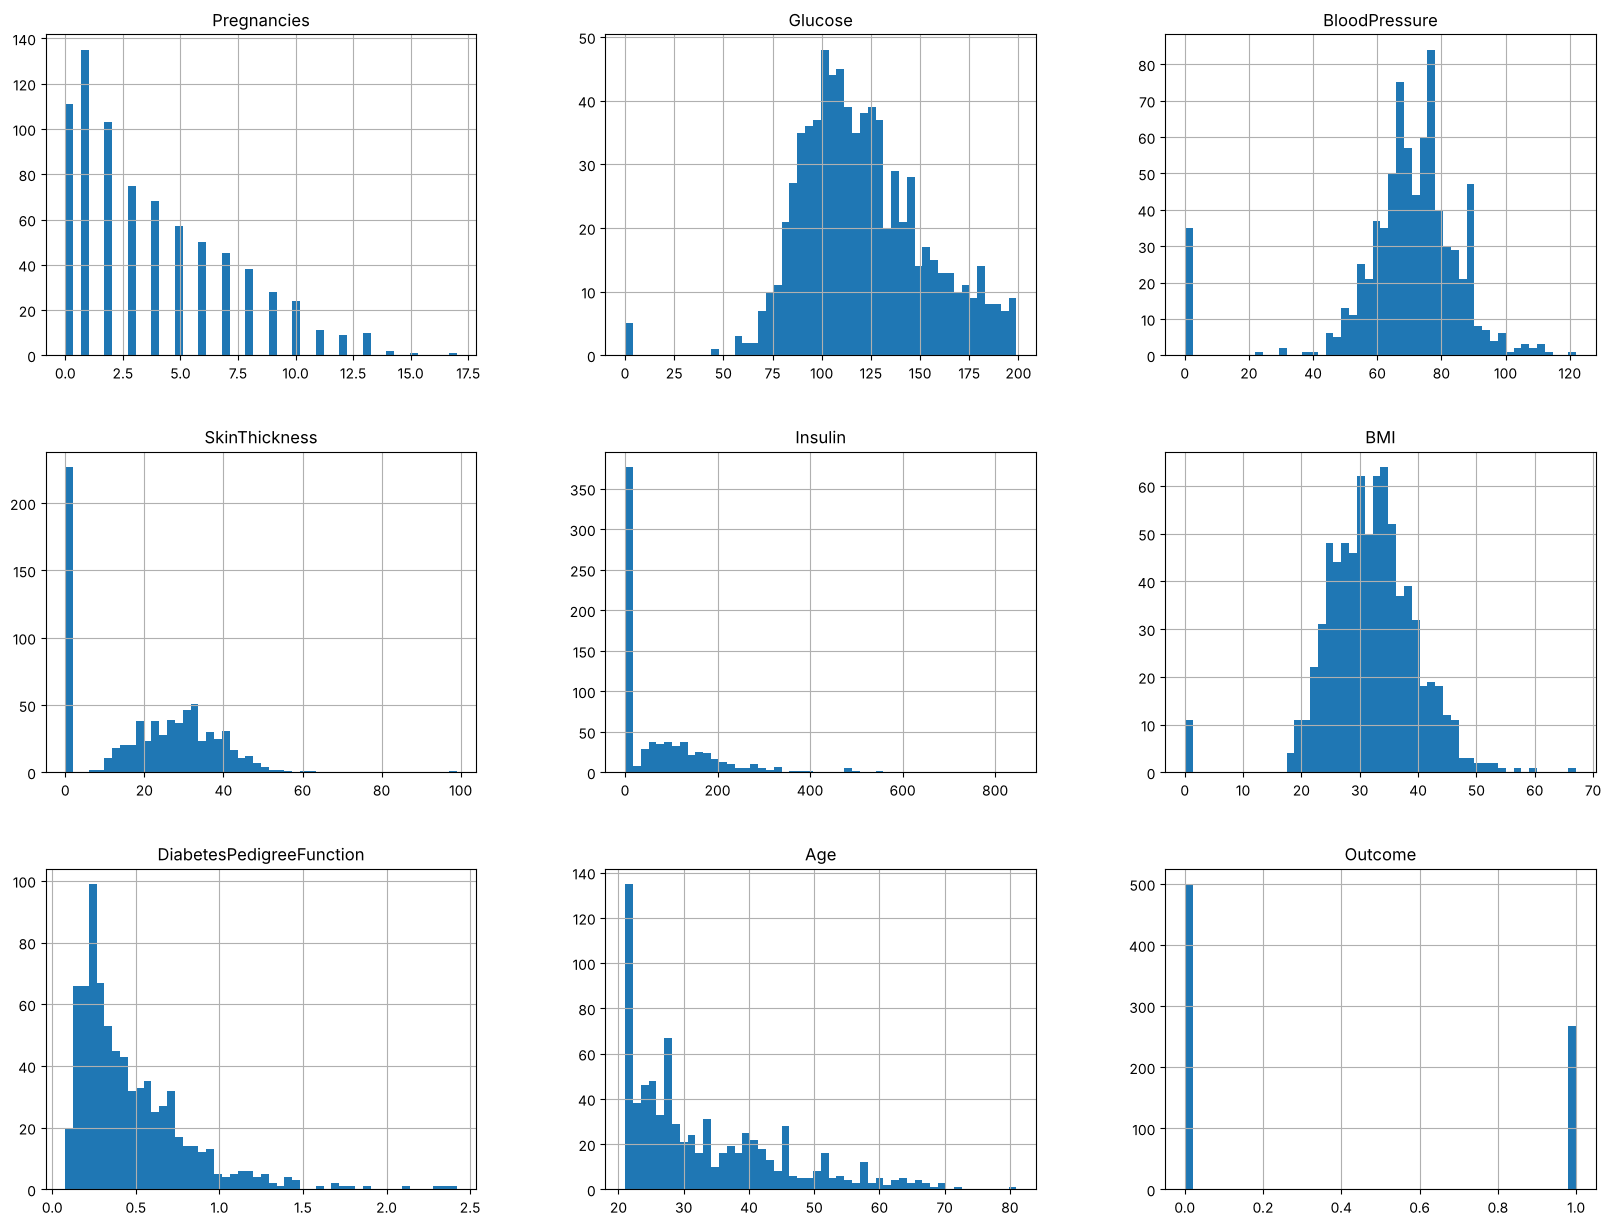

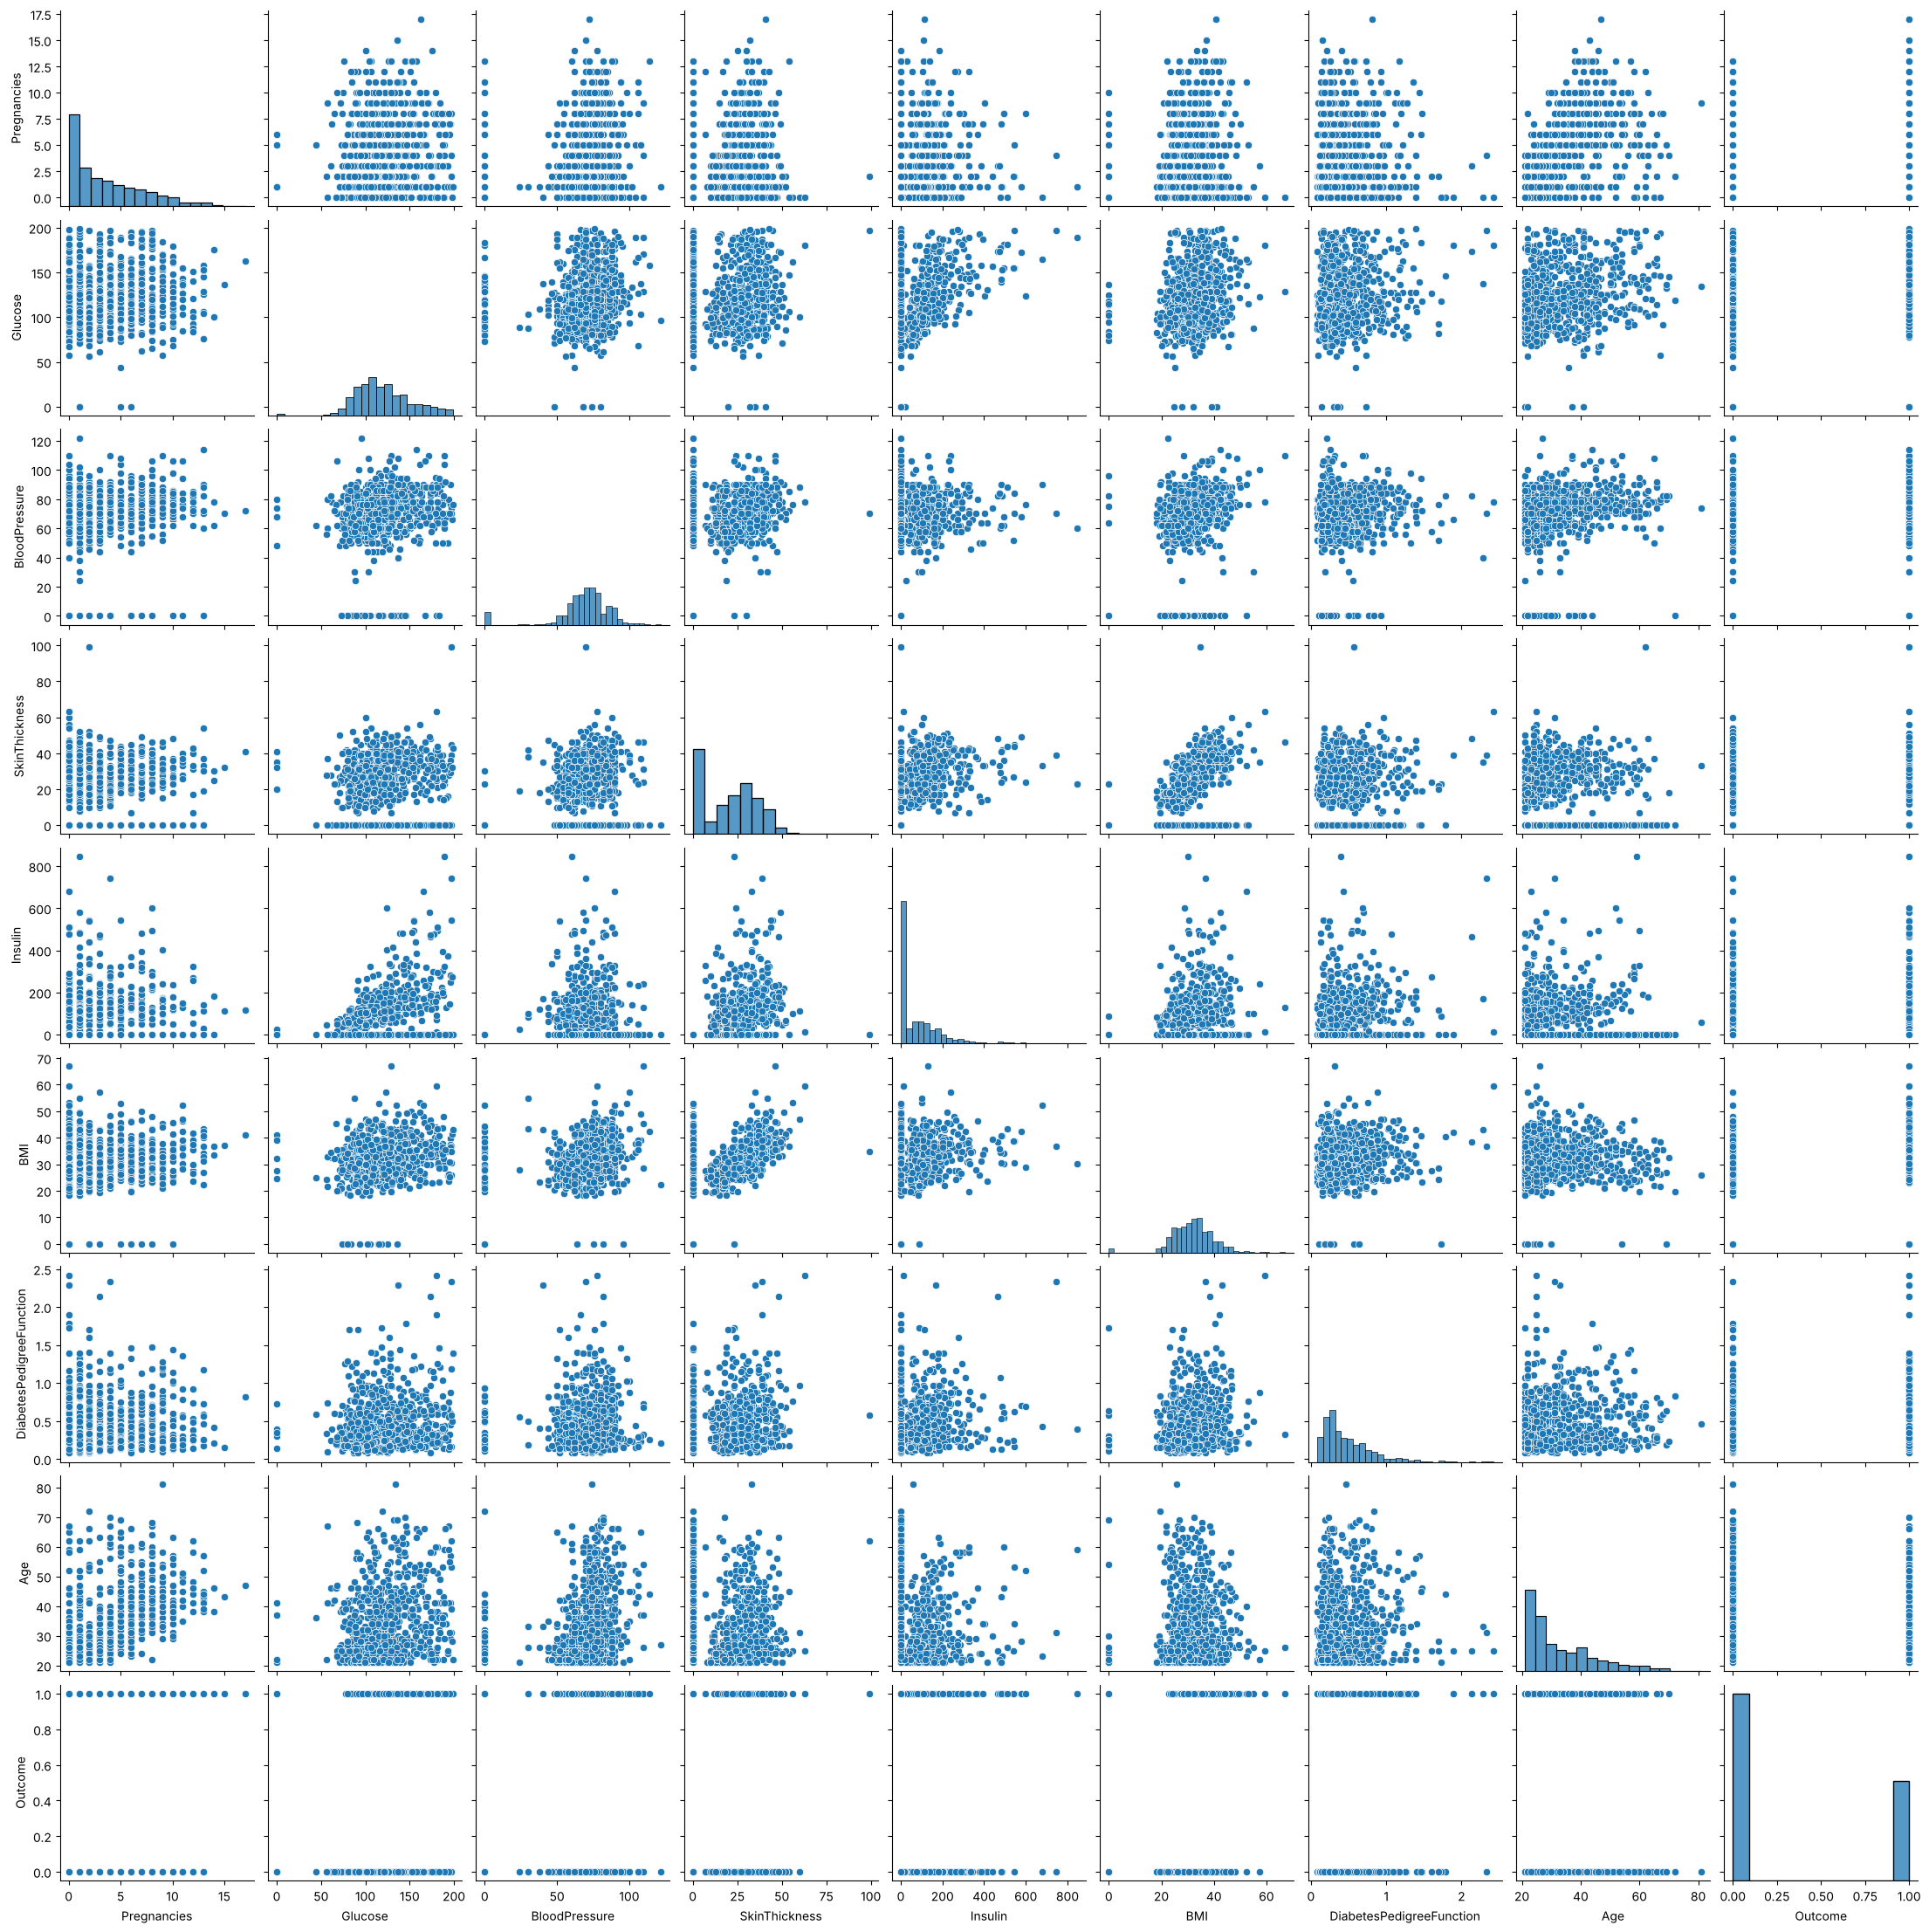

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

db = diabetes_df

# Dataset structure and summary statistics
print(db.info())
print(db.describe())

# Visualize the distribution of each feature
db.hist(bins=50, figsize=(20, 15))
plt.show()

# Pairplot to visualize relationships
sns.pairplot(db)
plt.show()

---
## Experiment 6: Time Series Analysis of Website Traffic

**Aim:** To analyse time-series data of website traffic to identify trends, seasonality and anomalies.

**Data:** if `website_traffic.csv` is not uploaded, the next cell creates 2 years of sample daily traffic (Date, Page_Views, Unique_Visitors, Bounce_Rate) with a trend, weekly pattern, a few missing values and a few traffic spikes.

In [17]:
import os
import numpy as np
import pandas as pd

if not os.path.exists('website_traffic.csv'):
    rng = np.random.default_rng(42)
    dates = pd.date_range('2022-01-01', '2023-12-31', freq='D')
    n = len(dates)
    weekday_effect = np.array([0, 40, 60, 50, 30, -120, -160])[np.asarray(dates.dayofweek)]
    yearly = 100 * np.sin(2 * np.pi * np.asarray(dates.dayofyear) / 365)
    page_views = np.linspace(1000, 1800, n) + weekday_effect + yearly + rng.normal(0, 40, n)
    page_views[[100, 250, 400, 600]] += [1400, 1600, 1500, 1300]          # traffic spikes (anomalies)
    unique = 0.6 * page_views + rng.normal(0, 30, n)
    bounce = 45 + rng.normal(0, 3, n)
    traffic = pd.DataFrame({'Date': dates, 'Page_Views': page_views.round(),
                            'Unique_Visitors': unique.round(), 'Bounce_Rate': bounce.round(2)})
    for c in ['Page_Views', 'Unique_Visitors', 'Bounce_Rate']:          # a few missing values
        traffic.loc[rng.choice(n, 5, replace=False), c] = np.nan
    traffic.to_csv('website_traffic.csv', index=False)
    print("Created sample website_traffic.csv")
else:
    print("Using your uploaded website_traffic.csv")

Created sample website_traffic.csv


#### 1. Load and clean data

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# Load dataset
data = pd.read_csv('website_traffic.csv', parse_dates=['Date'], index_col='Date')
print("Missing values before:\n", data.isnull().sum())

# Handle missing values by interpolation
data = data.asfreq('D').interpolate(method='time')
print("\nMissing values after:\n", data.isnull().sum())
data.head()

Missing values before:
 Page_Views         5
Unique_Visitors    5
Bounce_Rate        5
dtype: int64

Missing values after:
 Page_Views         0
Unique_Visitors    0
Bounce_Rate        0
dtype: int64


,Page_Views,Unique_Visitors,Bounce_Rate
Date,,,
2022-01-01,894.0,550.0,47.89
2022-01-02,803.0,484.0,42.83
2022-01-03,1037.0,639.0,42.44
2022-01-04,1088.0,647.0,46.38
2022-01-05,995.0,605.0,47.97


#### 2. Time series decomposition (trend, seasonality, residual)

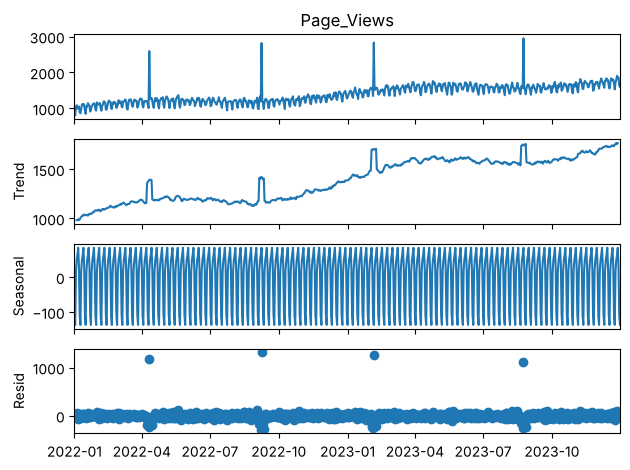

In [19]:
decomposition = seasonal_decompose(data['Page_Views'], model='additive', period=7)
decomposition.plot()
plt.show()

#### 3. Visualization: raw series, moving average and seasonal pattern

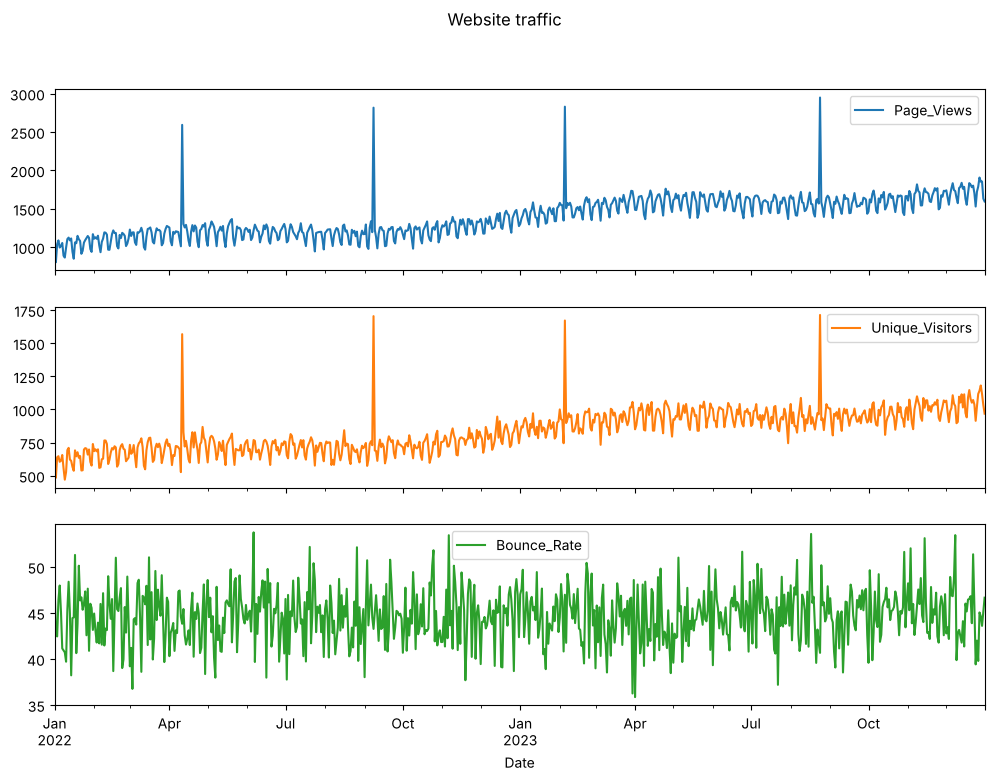

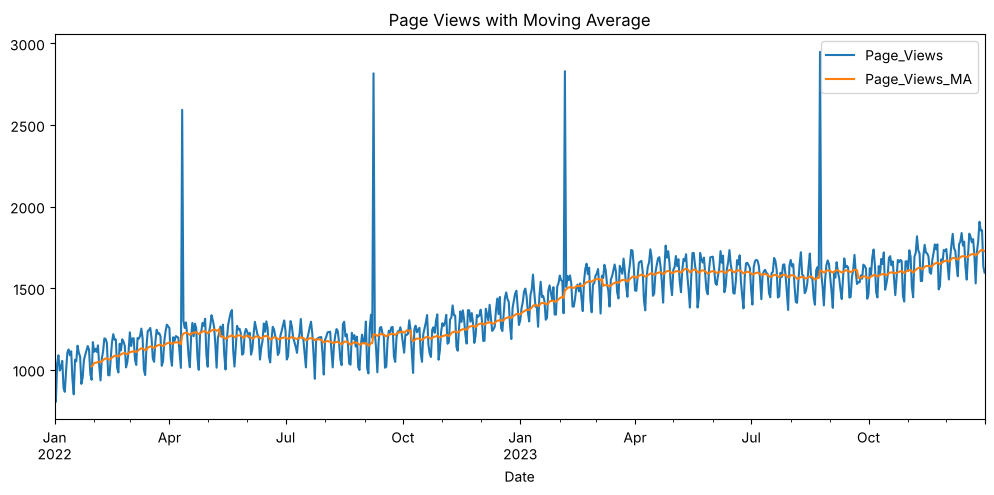

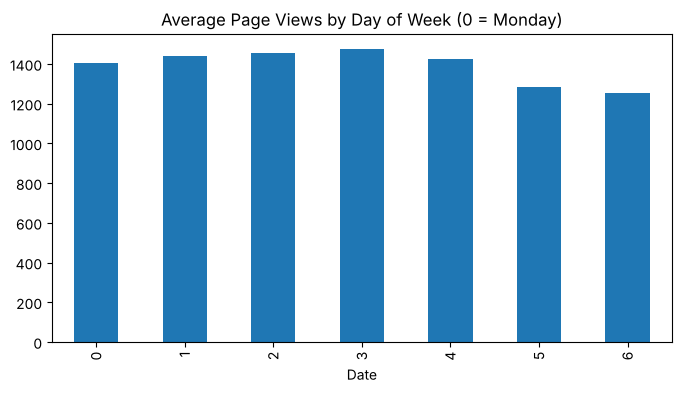

In [20]:
data[['Page_Views', 'Unique_Visitors', 'Bounce_Rate']].plot(subplots=True, figsize=(12, 8), title='Website traffic')
plt.show()

# Moving Average
data['Page_Views_MA'] = data['Page_Views'].rolling(window=30).mean()
data[['Page_Views', 'Page_Views_MA']].plot(figsize=(12, 5))
plt.title('Page Views with Moving Average')
plt.show()

# Seasonal pattern: average page views by day of week
data.groupby(data.index.dayofweek)['Page_Views'].mean().plot(kind='bar', figsize=(8, 4))
plt.title('Average Page Views by Day of Week (0 = Monday)')
plt.show()

#### 4. Anomaly detection using the Z-score

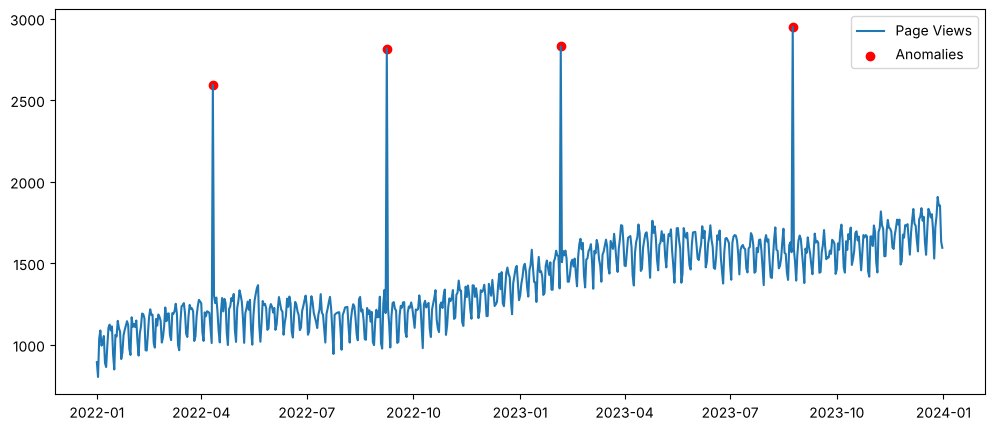

Number of anomalies found: 4


,Page_Views,Page_Views_Z
Date,,
2022-04-11,2593.0,4.750846
2022-09-08,2817.0,5.636329
2023-02-05,2830.0,5.687719
2023-08-24,2949.0,6.158131


In [21]:
data['Page_Views_Z'] = (data['Page_Views'] - data['Page_Views'].mean()) / data['Page_Views'].std()
anomalies = data[data['Page_Views_Z'].abs() > 3]

plt.figure(figsize=(12, 5))
plt.plot(data.index, data['Page_Views'], label='Page Views')
plt.scatter(anomalies.index, anomalies['Page_Views'], color='red', label='Anomalies')
plt.legend()
plt.show()
print("Number of anomalies found:", len(anomalies))
anomalies[['Page_Views', 'Page_Views_Z']]

---
## Experiment 7: Random Sampling and Sampling Distribution

**Aim:** To explore random sampling from a population and understand the sampling distribution (and the Central Limit Theorem).

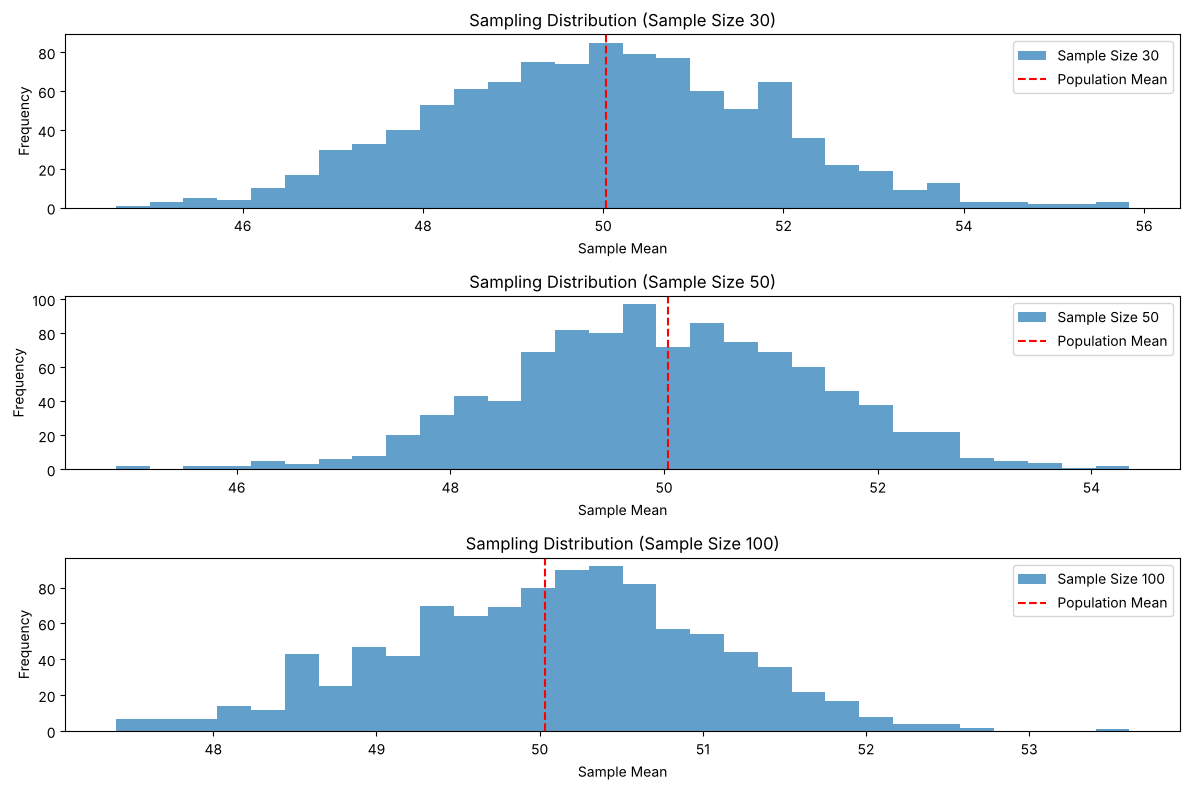

Population mean: 50.03 | Population std: 10.03
Sample size 30: mean of sample means = 49.95, std of sample means = 1.82  (theory: 1.83)
Sample size 50: mean of sample means = 50.00, std of sample means = 1.41  (theory: 1.41)
Sample size 100: mean of sample means = 50.06, std of sample means = 0.98  (theory: 1.00)


In [22]:
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Generate a population (normal distribution)
population_mean = 50
population_std = 10
population_size = 100000
population = np.random.normal(population_mean, population_std, population_size)

# Step 2: Random sampling
sample_sizes = [30, 50, 100]   # different sample sizes to consider
num_samples = 1000             # number of samples for each sample size

sample_means = {}
for size in sample_sizes:
    sample_means[size] = []
    for _ in range(num_samples):
        sample = np.random.choice(population, size=size, replace=False)
        sample_means[size].append(np.mean(sample))

# Step 3: Plotting sampling distributions
plt.figure(figsize=(12, 8))
for i, size in enumerate(sample_sizes):
    plt.subplot(len(sample_sizes), 1, i + 1)
    plt.hist(sample_means[size], bins=30, alpha=0.7, label=f'Sample Size {size}')
    plt.axvline(np.mean(population), color='red', linestyle='dashed', linewidth=1.5, label='Population Mean')
    plt.title(f'Sampling Distribution (Sample Size {size})')
    plt.xlabel('Sample Mean')
    plt.ylabel('Frequency')
    plt.legend()
plt.tight_layout()
plt.show()

# Compare statistics: the spread of the sample means shrinks as the sample size grows
print("Population mean:", round(population.mean(), 2), "| Population std:", round(population.std(), 2))
for size in sample_sizes:
    print(f"Sample size {size}: mean of sample means = {np.mean(sample_means[size]):.2f}, "
          f"std of sample means = {np.std(sample_means[size]):.2f}  (theory: {population_std/np.sqrt(size):.2f})")

**Step 4 (optional) – Central Limit Theorem:** even for a skewed (exponential) population, the sample means become normal as the sample size grows.

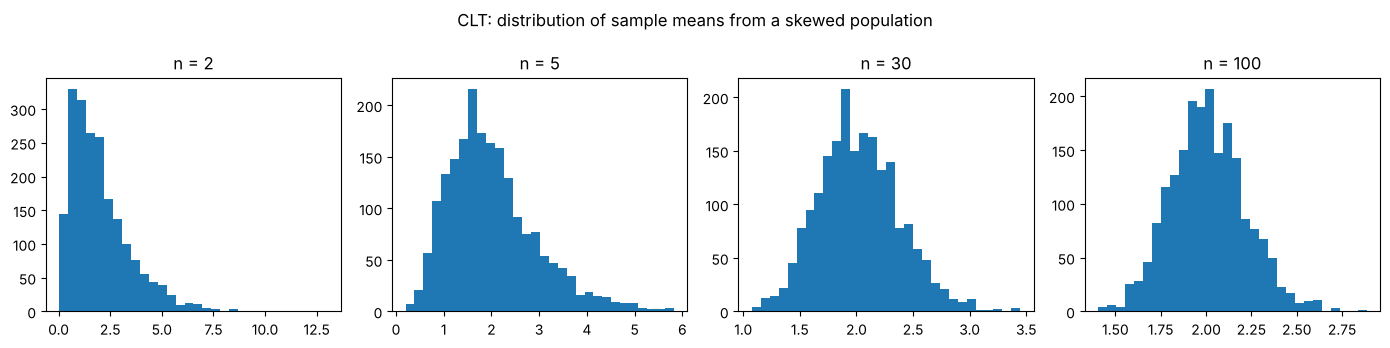

In [23]:
skewed_population = np.random.exponential(scale=2.0, size=100000)
plt.figure(figsize=(14, 3.5))
for i, size in enumerate([2, 5, 30, 100]):
    means = [np.mean(np.random.choice(skewed_population, size)) for _ in range(2000)]
    plt.subplot(1, 4, i + 1)
    plt.hist(means, bins=30)
    plt.title(f'n = {size}')
plt.suptitle('CLT: distribution of sample means from a skewed population')
plt.tight_layout()
plt.show()

---
## Experiment 8: Z-Test in Python

**Aim:** To test whether the average weight of a species of birds differs from 150 grams (H0: mean = 150 g, H1: mean ≠ 150 g, α = 0.05).

In [24]:
import numpy as np
import scipy.stats as stats

# Sample data (hypothetical weights in grams) - 30 birds
sample_data = np.array([152, 148, 151, 149, 147, 153, 150, 148, 152, 149, 151, 150, 149, 152, 151,
                        148, 150, 152, 149, 150, 148, 153, 151, 150, 149, 152, 148, 151, 150, 153])

# Population mean under the null hypothesis
population_mean = 150

# Calculate sample statistics
sample_mean = np.mean(sample_data)
sample_std = np.std(sample_data, ddof=1)   # sample standard deviation
n = len(sample_data)

# Calculate the Z-statistic
z_statistic = (sample_mean - population_mean) / (sample_std / np.sqrt(n))

# Calculate the p-value (two-tailed test)
p_value = 2 * (1 - stats.norm.cdf(np.abs(z_statistic)))

# Print results
print(f"Sample Mean: {sample_mean:.2f}")
print(f"Z-Statistic: {z_statistic:.4f}")
print(f"P-Value: {p_value:.4f}")

# Decision based on the significance level
alpha = 0.05
if p_value < alpha:
    print("Reject the null hypothesis: The average weight is significantly different from 150 grams.")
else:
    print("Fail to reject the null hypothesis: There is no significant difference in average weight from 150 grams.")

Sample Mean: 150.20
Z-Statistic: 0.6406
P-Value: 0.5218
Fail to reject the null hypothesis: There is no significant difference in average weight from 150 grams.


---
## Experiment 9: Matplotlib / Seaborn Visualization on the Iris Data Set

**Aim:** To understand Matplotlib (with Seaborn) use cases in Data Science through visualization of the Iris data set.

**Data:** the cell below builds `Iris_Dataset.csv` (150 rows, same columns as in the manual) from scikit-learn's built-in Iris data, unless you have uploaded your own copy.

In [25]:
import os
import pandas as pd
from sklearn.datasets import load_iris

if not os.path.exists('Iris_Dataset.csv'):
    iris = load_iris(as_frame=True)
    d = iris.frame.copy()
    d.columns = ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'target']
    d['variety'] = d['target'].map({0: 'Iris-setosa', 1: 'Iris-versicolor', 2: 'Iris-virginica'})
    d.insert(0, 'Id', range(1, len(d) + 1))
    d.drop(columns='target').to_csv('Iris_Dataset.csv', index=False)
    print("Created Iris_Dataset.csv")
else:
    print("Using your uploaded Iris_Dataset.csv")

Created Iris_Dataset.csv


In [26]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

data = pd.read_csv('Iris_Dataset.csv')
data

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,variety
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...,...
145,146,6.7,3.0,5.2,2.3,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
147,148,6.5,3.0,5.2,2.0,Iris-virginica
148,149,6.2,3.4,5.4,2.3,Iris-virginica


In [27]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   variety        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB


In [28]:
data.describe()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.057333,3.758000,1.199333
std,43.445368,0.828066,0.435866,1.765298,0.762238
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


In [29]:
data.value_counts('variety')

variety
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

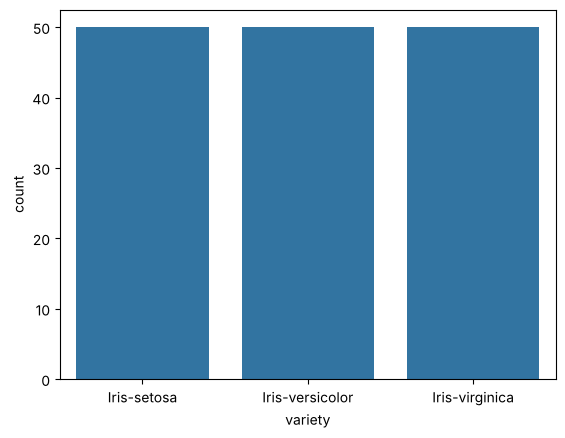

,Iris-setosa,Iris-versicolor,Iris-virginica,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm
0,True,False,False,1,5.1,3.5,1.4
1,True,False,False,2,4.9,3.0,1.4
2,True,False,False,3,4.7,3.2,1.3
3,True,False,False,4,4.6,3.1,1.5
4,True,False,False,5,5.0,3.6,1.4


In [30]:
sns.countplot(x='variety', data=data)
plt.show()

dummies = pd.get_dummies(data.variety)
FinalDataset = pd.concat([pd.get_dummies(data.variety), data.iloc[:, [0, 1, 2, 3]]], axis=1)
FinalDataset.head()

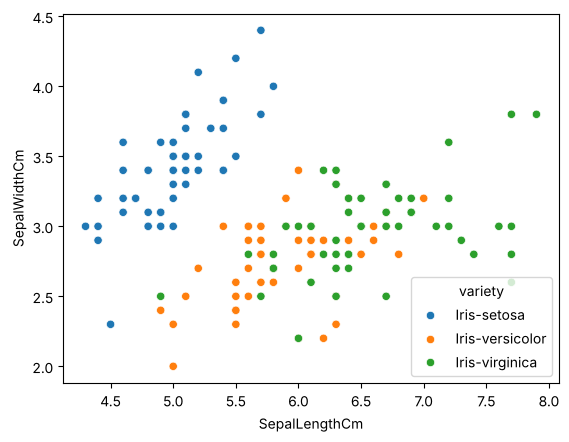

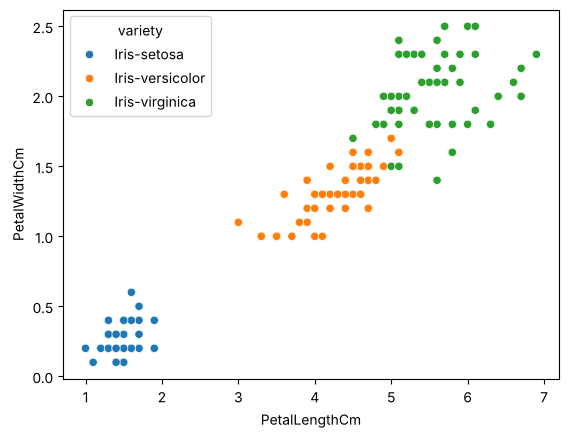

In [31]:
sns.scatterplot(x='SepalLengthCm', y='SepalWidthCm', hue='variety', data=data)
plt.show()
sns.scatterplot(x='PetalLengthCm', y='PetalWidthCm', hue='variety', data=data)
plt.show()

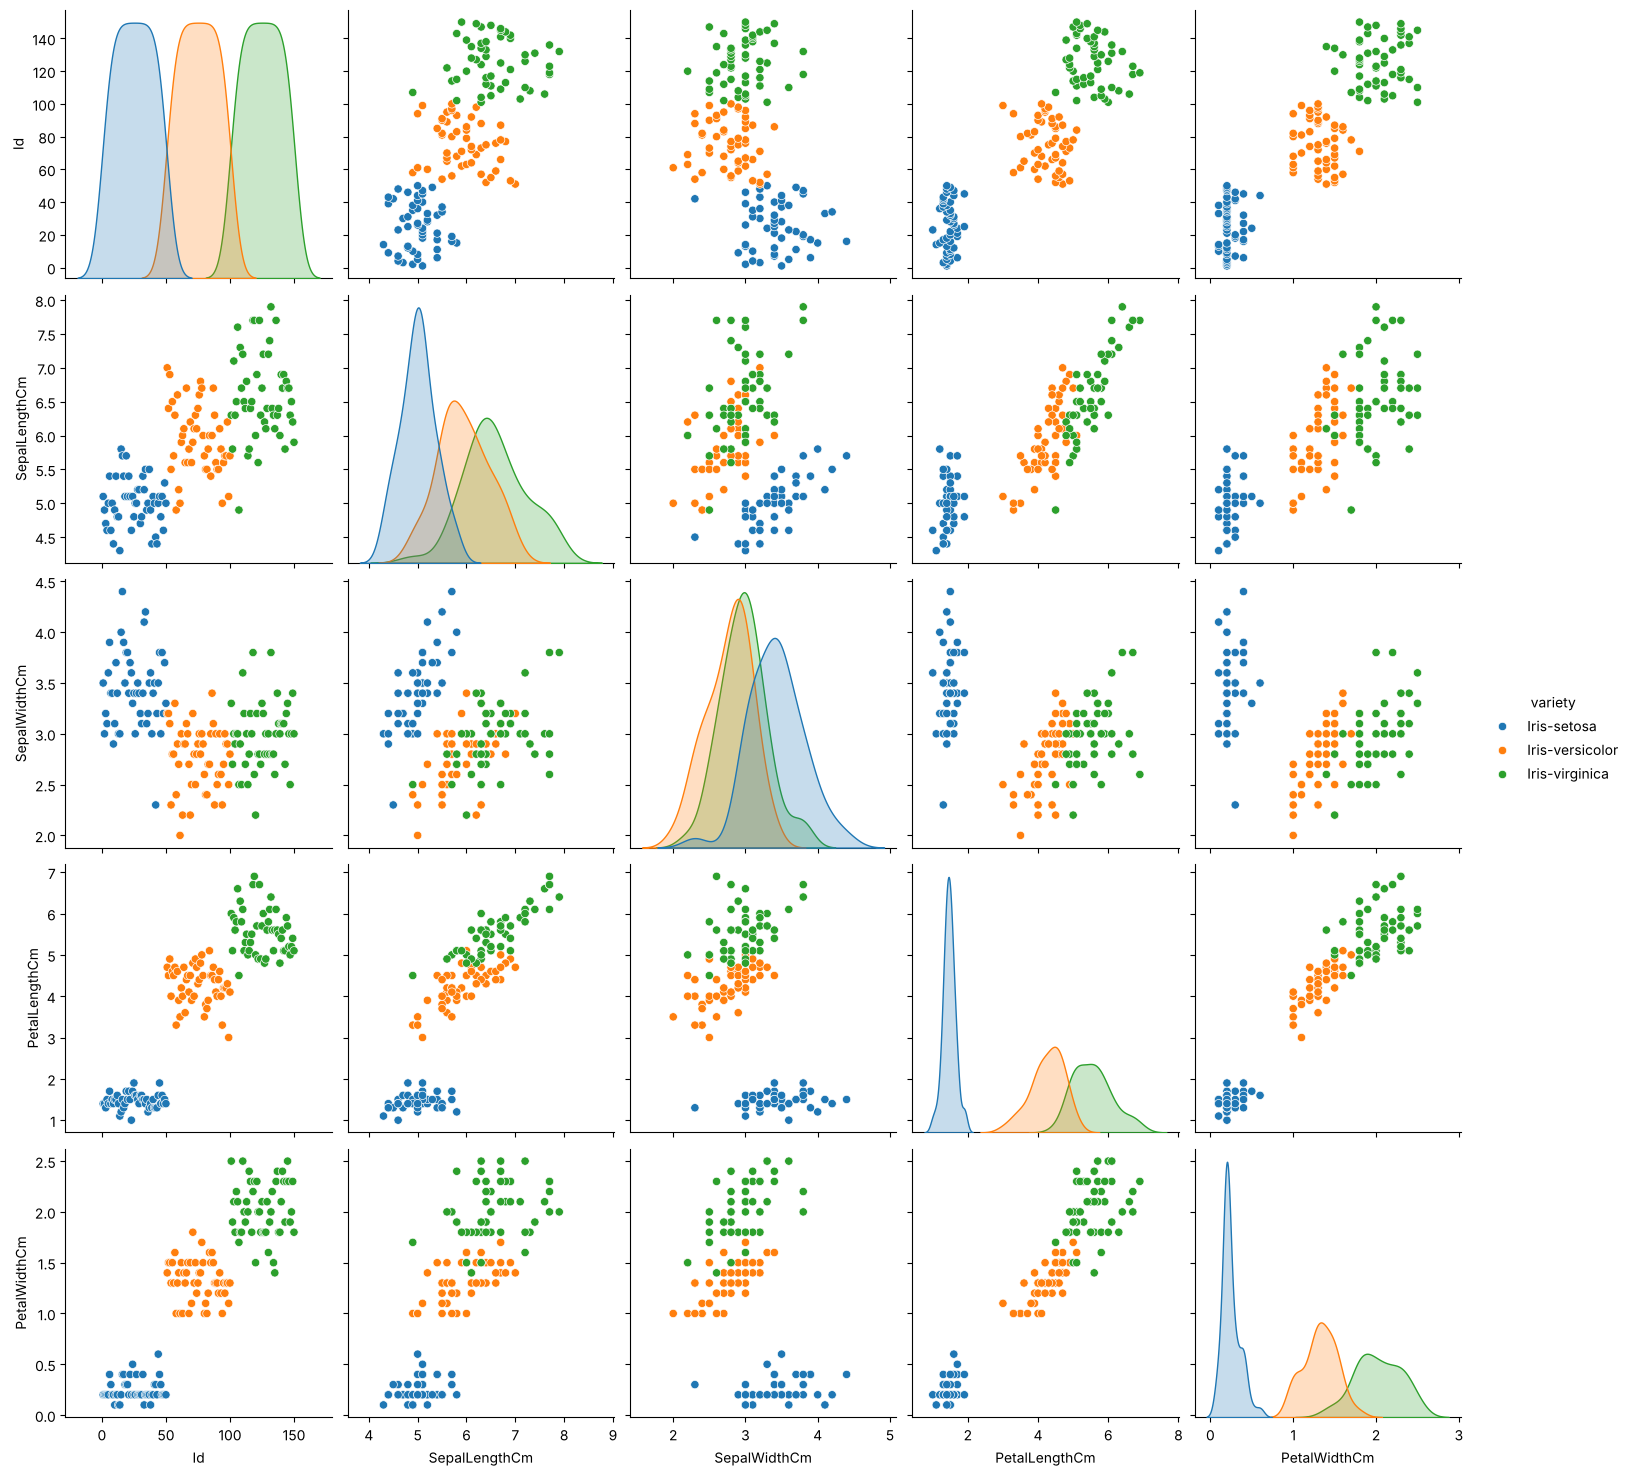

In [32]:
sns.pairplot(data, hue='variety', height=3)
plt.show()

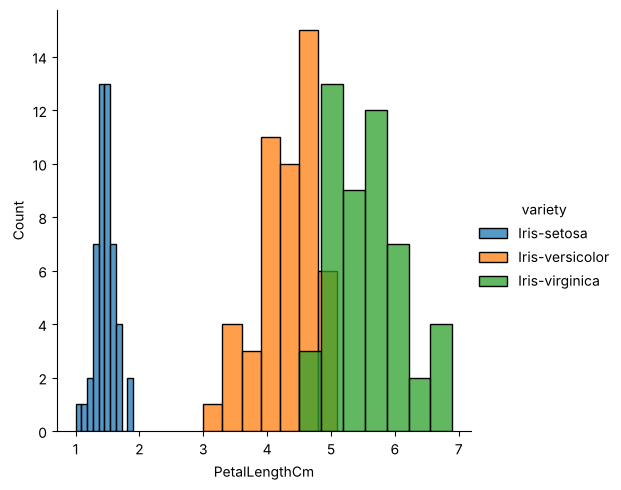

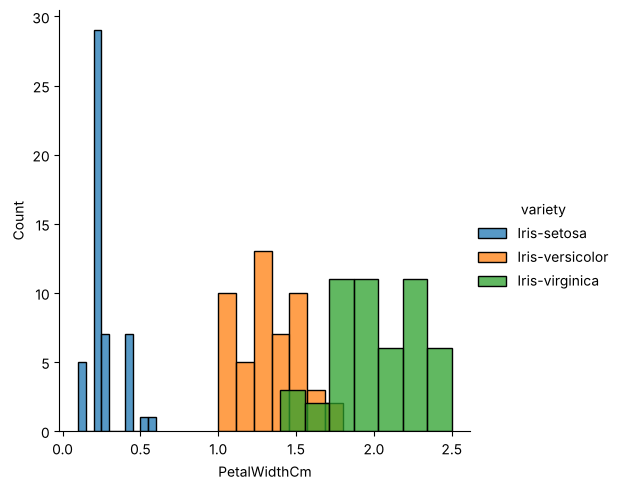

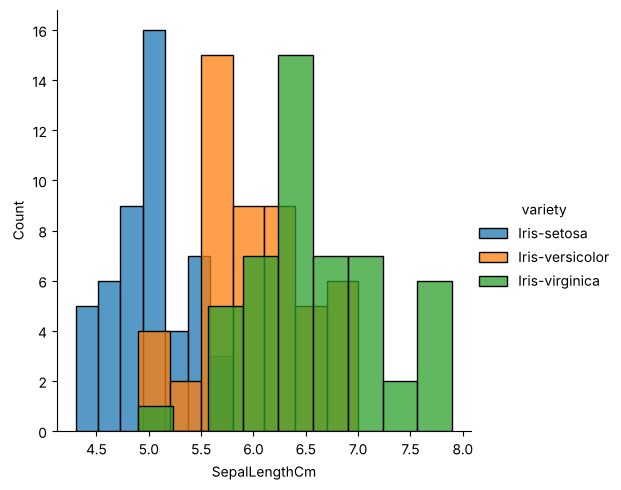

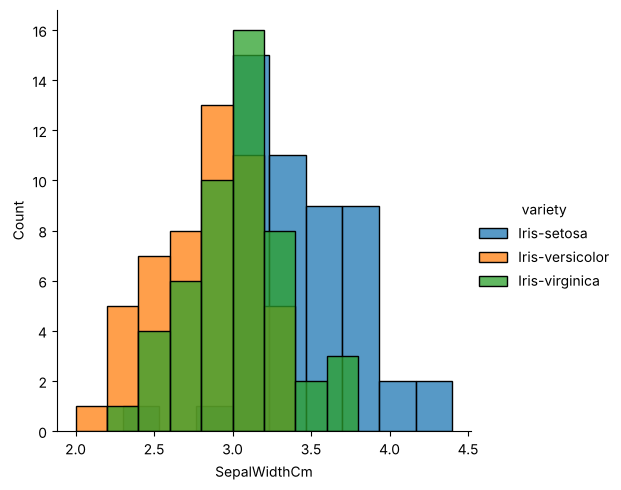

In [33]:
sns.FacetGrid(data, hue='variety', height=5).map(sns.histplot, 'PetalLengthCm').add_legend()
plt.show()
sns.FacetGrid(data, hue='variety', height=5).map(sns.histplot, 'PetalWidthCm').add_legend()
plt.show()
sns.FacetGrid(data, hue='variety', height=5).map(sns.histplot, 'SepalLengthCm').add_legend()
plt.show()
sns.FacetGrid(data, hue='variety', height=5).map(sns.histplot, 'SepalWidthCm').add_legend()
plt.show()

---
## Experiment 10: NumPy Array Functions

**Aim:** To understand array functions in Data Science using the NumPy library.

In [34]:
import numpy as np

array = np.random.randint(1, 100, 9)
array

array([59,  7, 99, 48, 83,  2, 58, 91, 97])

In [35]:
np.sqrt(array)

array([7.68114575, 2.64575131, 9.94987437, 6.92820323, 9.11043358,
       1.41421356, 7.61577311, 9.53939201, 9.8488578 ])

In [36]:
array.ndim

1

In [37]:
new_array = array.reshape(3, 3)
new_array

array([[59,  7, 99],
       [48, 83,  2],
       [58, 91, 97]])

In [38]:
new_array.ndim

2

In [39]:
new_array.ravel()

array([59,  7, 99, 48, 83,  2, 58, 91, 97])

In [40]:
newm = new_array.reshape(3, 3)
newm

array([[59,  7, 99],
       [48, 83,  2],
       [58, 91, 97]])

Indexing and slicing:

In [41]:
print("newm[2,1:3]   ->", newm[2, 1:3])
print("newm[1:2,1:3] ->", newm[1:2, 1:3])
print("new_array[0:3,0:0] ->", new_array[0:3, 0:0])
print("new_array[0:2,0:1] ->\n", new_array[0:2, 0:1])
print("new_array[0:3,0:1] ->\n", new_array[0:3, 0:1])
print("new_array[1:3] ->\n", new_array[1:3])

newm[2,1:3]   -> [91 97]
newm[1:2,1:3] -> [[83  2]]
new_array[0:3,0:0] -> []
new_array[0:2,0:1] ->
 [[59]
 [48]]
new_array[0:3,0:1] ->
 [[59]
 [48]
 [58]]
new_array[1:3] ->
 [[48 83  2]
 [58 91 97]]


---
## Experiment 11: Pandas Library Use Cases

**Aim:** To understand DataFrame use cases in Data Science using the pandas library.

#### Creating a DataFrame from a list

In [42]:
import numpy as np
import pandas as pd

list = [[1, 'Smith', 50000], [2, 'Jones', 60000]]
df = pd.DataFrame(list)
df

,0,1,2
0,1,Smith,50000
1,2,Jones,60000


In [43]:
df.columns = ['Empd', 'Name', 'Salary']
df

,Empd,Name,Salary
0,1,Smith,50000
1,2,Jones,60000


In [44]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Empd    2 non-null      int64
 1   Name    2 non-null      str  
 2   Salary  2 non-null      int64
dtypes: int64(2), str(1)
memory usage: 180.0 bytes


#### Reading a CSV file (50_Startups.csv)

If `50_Startups.csv` is not uploaded, a 50-row sample with the same columns is created.

In [45]:
import os, numpy as np, pandas as pd

if not os.path.exists('50_Startups.csv'):
    rng = np.random.default_rng(1)
    n = 50
    rd = rng.uniform(0, 165349, n).round(2)
    adm = rng.uniform(51000, 182000, n).round(2)
    mkt = rng.uniform(0, 471784, n).round(2)
    state = rng.choice(['New York', 'California', 'Florida'], n)
    profit = (40000 + 0.85 * rd + 0.05 * adm + 0.1 * mkt + rng.normal(0, 8000, n)).round(2)
    pd.DataFrame({'R&D Spend': rd, 'Administration': adm, 'Marketing Spend': mkt,
                  'State': state, 'Profit': profit}).to_csv('50_Startups.csv', index=False)
    print("Created sample 50_Startups.csv")

df = pd.read_csv("50_Startups.csv")
df.info()

Created sample 50_Startups.csv
<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   R&D Spend        50 non-null     float64
 1   Administration   50 non-null     float64
 2   Marketing Spend  50 non-null     float64
 3   State            50 non-null     str    
 4   Profit           50 non-null     float64
dtypes: float64(4), str(1)
memory usage: 2.1 KB


In [46]:
df.head()

,R&D Spend,Administration,Marketing Spend,State,Profit
0,84629.19,140510.58,308483.52,New York,149568.47
1,157158.22,154109.70,203445.88,Florida,203026.29
2,23836.65,76101.73,409187.94,California,91618.23
3,156858.24,156109.71,298231.23,California,217595.14
4,51561.02,76063.43,382274.47,Florida,121259.57


In [47]:
df.tail()

,R&D Spend,Administration,Marketing Spend,State,Profit
45,84244.63,106175.73,370390.68,California,152300.65
46,84474.97,64875.68,139179.32,California,126295.63
47,124512.79,133943.95,362694.22,California,189256.01
48,24458.76,100835.58,247983.60,California,88285.27
49,135524.46,146013.51,70318.47,California,175554.00


#### Employee data: Series, statistics and conversion to/from NumPy

In [48]:
import os, pandas as pd

if not os.path.exists('employee.csv'):
    pd.DataFrame({'emp id': [1, 2, 3, 4, 5, 6, 7],
                  'name': ['SREE VARSSINI K S', 'SREEMATHI B', 'SREYA G', 'SREYASKARI MULLAPUDI',
                           'SRI AKASH U G', 'SRI HARSHAVARDHANAN R', 'SRI HARSHAVARDHANAN R'],
                  'salary': [5000, 6000, 7000, 5000, 8000, 3000, 6000]}).to_csv('employee.csv', index=False)

df = pd.read_csv("employee.csv")
df.head()

,emp id,name,salary
0,1,SREE VARSSINI K S,5000
1,2,SREEMATHI B,6000
2,3,SREYA G,7000
3,4,SREYASKARI MULLAPUDI,5000
4,5,SRI AKASH U G,8000


In [49]:
df.tail()

,emp id,name,salary
2,3,SREYA G,7000
3,4,SREYASKARI MULLAPUDI,5000
4,5,SRI AKASH U G,8000
5,6,SRI HARSHAVARDHANAN R,3000
6,7,SRI HARSHAVARDHANAN R,6000


In [50]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   emp id  7 non-null      int64
 1   name    7 non-null      str  
 2   salary  7 non-null      int64
dtypes: int64(2), str(1)
memory usage: 300.0 bytes


In [51]:
print(df.salary)
print(type(df.salary))

0    5000
1    6000
2    7000
3    5000
4    8000
5    3000
6    6000
Name: salary, dtype: int64
<class 'pandas.Series'>


In [52]:
print("Mean   :", df.salary.mean())
print("Median :", df.salary.median())
print("Mode   :\n", df.salary.mode())
print("Var    :", df.salary.var())
print("Std    :", df.salary.std())

Mean   : 5714.285714285715
Median : 6000.0
Mode   :
 0    5000
1    6000
Name: salary, dtype: int64
Var    : 2571428.5714285714
Std    : 1603.5674514745463


In [53]:
df.describe()

,emp id,salary
count,7.000000,7.000000
mean,4.000000,5714.285714
std,2.160247,1603.567451
min,1.000000,3000.000000
25%,2.500000,5000.000000
50%,4.000000,6000.000000
75%,5.500000,6500.000000
max,7.000000,8000.000000


In [54]:
df.describe(include='all')

,emp id,name,salary
count,7.000000,7,7.000000
unique,NaN,6,NaN
top,NaN,SRI HARSHAVARDHANAN R,NaN
freq,NaN,2,NaN
mean,4.000000,NaN,5714.285714
std,2.160247,NaN,1603.567451
min,1.000000,NaN,3000.000000
25%,2.500000,NaN,5000.000000
50%,4.000000,NaN,6000.000000
75%,5.500000,NaN,6500.000000


In [55]:
empCol = df.columns
print(empCol)
emparray = df.values
print(emparray)
employee_DF = pd.DataFrame(emparray, columns=empCol)
employee_DF

Index(['emp id', 'name', 'salary'], dtype='str')
[[1 'SREE VARSSINI K S' 5000]
 [2 'SREEMATHI B' 6000]
 [3 'SREYA G' 7000]
 [4 'SREYASKARI MULLAPUDI' 5000]
 [5 'SRI AKASH U G' 8000]
 [6 'SRI HARSHAVARDHANAN R' 3000]
 [7 'SRI HARSHAVARDHANAN R' 6000]]


,emp id,name,salary
0,1,SREE VARSSINI K S,5000
1,2,SREEMATHI B,6000
2,3,SREYA G,7000
3,4,SREYASKARI MULLAPUDI,5000
4,5,SRI AKASH U G,8000
5,6,SRI HARSHAVARDHANAN R,3000
6,7,SRI HARSHAVARDHANAN R,6000


---
## Experiment 12: Outlier Detection (IQR Method)

**Aim:** To understand the procedure to identify outliers in a given data set using percentiles and the Inter-Quartile Range.

In [56]:
# sample calculation for lower range (lr), upper range (ur) and percentiles
import numpy as np

array = np.random.randint(1, 100, 16)   # randomly generate 16 numbers between 1 and 100
print(array)
print("Mean:", array.mean())
print("25th percentile:", np.percentile(array, 25))
print("50th percentile:", np.percentile(array, 50))
print("75th percentile:", np.percentile(array, 75))
print("100th percentile:", np.percentile(array, 100))

[23 63 66 19 62 61 42  3 58 70 54 62  9 15 94 72]
Mean: 48.3125
25th percentile: 22.0
50th percentile: 59.5
75th percentile: 63.75
100th percentile: 94.0


In [57]:
# outlier detection function
def outDetection(array):
    sorted(array)
    Q1, Q3 = np.percentile(array, [25, 75])
    IQR = Q3 - Q1
    lr = Q1 - (1.5 * IQR)
    ur = Q3 + (1.5 * IQR)
    return lr, ur

lr, ur = outDetection(array)
print("Lower range:", lr, " Upper range:", ur)

Lower range: -40.625  Upper range: 126.375


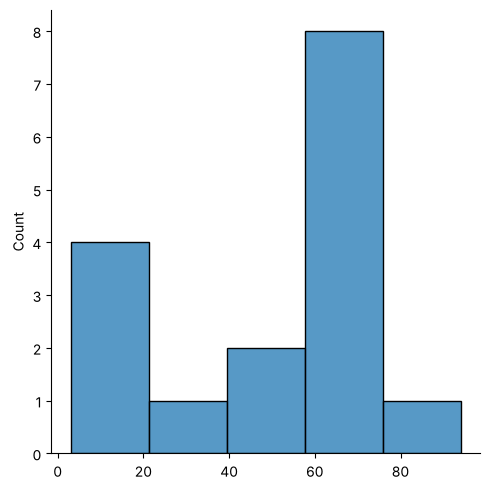

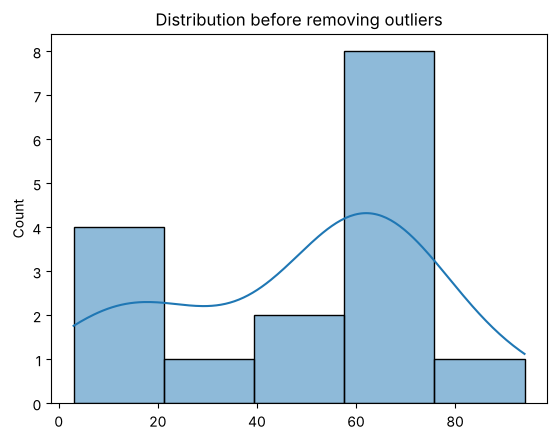

In [58]:
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

sns.displot(array)
plt.show()
sns.histplot(array, kde=True)
plt.title("Distribution before removing outliers")
plt.show()

[23 63 66 19 62 61 42  3 58 70 54 62  9 15 94 72]


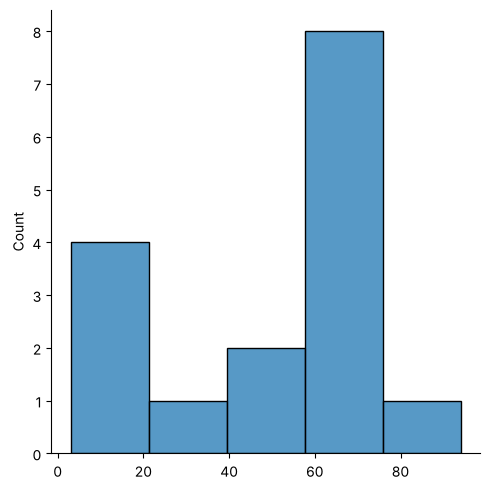

Lower range: -40.625  Upper range: 126.375
[23 63 66 19 62 61 42  3 58 70 54 62  9 15 94 72]


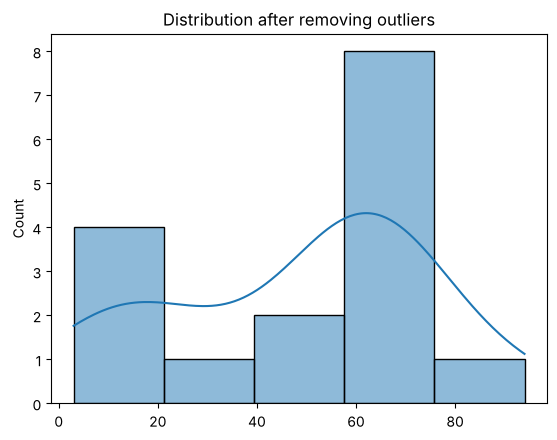

In [59]:
new_array = array[(array > lr) & (array < ur)]
print(new_array)
sns.displot(new_array)
plt.show()

lr1, ur1 = outDetection(new_array)
print("Lower range:", lr1, " Upper range:", ur1)
final_array = new_array[(new_array > lr1) & (new_array < ur1)]
print(final_array)
sns.histplot(final_array, kde=True)
plt.title("Distribution after removing outliers")
plt.show()

**Demonstration with real outliers:** random numbers between 1 and 100 usually contain no outliers, so here we add two extreme values (250 and -40) and remove them with the same method.

Lower range: 28.5  Upper range: 74.5
Removed outliers: [250 -40]


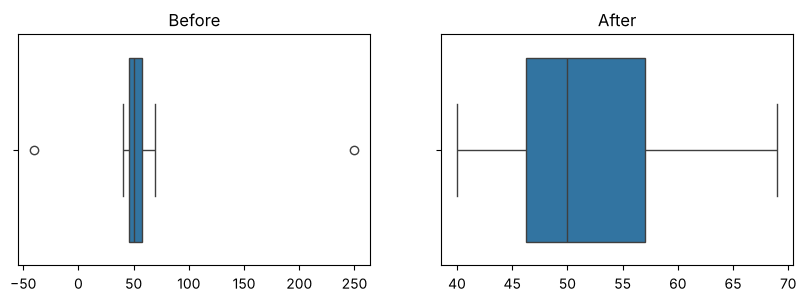

In [60]:
with_outliers = np.append(np.random.randint(40, 70, 30), [250, -40])
lr2, ur2 = outDetection(with_outliers)
cleaned = with_outliers[(with_outliers > lr2) & (with_outliers < ur2)]
print("Lower range:", lr2, " Upper range:", ur2)
print("Removed outliers:", with_outliers[(with_outliers <= lr2) | (with_outliers >= ur2)])

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
sns.boxplot(x=with_outliers, ax=ax[0]); ax[0].set_title("Before")
sns.boxplot(x=cleaned, ax=ax[1]); ax[1].set_title("After")
plt.show()

---
## Experiment 13: Handling Missing Values and Inappropriate Data

**Aim:** To handle missing data and inappropriate data in a data set using the pandas library (data preprocessing).

**Dataset:** `Hotel_Dataset.csv` – created below exactly as given in the manual (it has a duplicate row, a wrong spelling *Ibys*, inconsistent food labels and impossible values such as negative bills).

In [61]:
import pandas as pd

hotel_csv = """CustomerID,Age_Group,Rating(1-5),Hotel,FoodPreference,Bill,NoOfPax,EstimatedSalary,Age_Group.1
1,20-25,4,Ibis,veg,1300,2,40000,20-25
2,30-35,5,LemonTree,Non-Veg,2000,3,59000,30-35
3,25-30,6,RedFox,Veg,1322,2,30000,25-30
4,20-25,-1,LemonTree,Veg,1234,2,120000,20-25
5,35+,3,Ibis,Vegetarian,989,2,45000,35+
6,35+,3,Ibys,Non-Veg,1909,2,122220,35+
7,35+,4,RedFox,Vegetarian,1000,-1,21122,35+
8,20-25,7,LemonTree,Veg,2999,-10,345673,20-25
9,25-30,2,Ibis,Non-Veg,3456,3,-99999,25-30
9,25-30,2,Ibis,Non-Veg,3456,3,-99999,25-30
10,30-35,5,RedFox,non-Veg,6755,4,87777,30-35
"""
open("Hotel_Dataset.csv", "w").write(hotel_csv)

565

In [62]:
import numpy as np
import pandas as pd

# Load Hotel_Dataset.csv into a DataFrame
df = pd.read_csv("Hotel_Dataset.csv")
df

,CustomerID,Age_Group,Rating(1-5),Hotel,FoodPreference,Bill,NoOfPax,EstimatedSalary,Age_Group.1
0,1,20-25,4,Ibis,veg,1300,2,40000,20-25
1,2,30-35,5,LemonTree,Non-Veg,2000,3,59000,30-35
2,3,25-30,6,RedFox,Veg,1322,2,30000,25-30
3,4,20-25,-1,LemonTree,Veg,1234,2,120000,20-25
4,5,35+,3,Ibis,Vegetarian,989,2,45000,35+
5,6,35+,3,Ibys,Non-Veg,1909,2,122220,35+
6,7,35+,4,RedFox,Vegetarian,1000,-1,21122,35+
7,8,20-25,7,LemonTree,Veg,2999,-10,345673,20-25
8,9,25-30,2,Ibis,Non-Veg,3456,3,-99999,25-30
9,9,25-30,2,Ibis,Non-Veg,3456,3,-99999,25-30


In [63]:
# Identify the duplicate row (row 9): duplicated() returns True for repeated rows
df.duplicated()

0     False
1     False
2     False
3     False
4     False
5     False
6     False
7     False
8     False
9      True
10    False
dtype: bool

In [64]:
# info(): columns, data types, non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11 entries, 0 to 10
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   CustomerID       11 non-null     int64
 1   Age_Group        11 non-null     str  
 2   Rating(1-5)      11 non-null     int64
 3   Hotel            11 non-null     str  
 4   FoodPreference   11 non-null     str  
 5   Bill             11 non-null     int64
 6   NoOfPax          11 non-null     int64
 7   EstimatedSalary  11 non-null     int64
 8   Age_Group.1      11 non-null     str  
dtypes: int64(5), str(4)
memory usage: 924.0 bytes


In [65]:
# drop_duplicates() removes duplicate rows
df.drop_duplicates(inplace=True)
df

,CustomerID,Age_Group,Rating(1-5),Hotel,FoodPreference,Bill,NoOfPax,EstimatedSalary,Age_Group.1
0,1,20-25,4,Ibis,veg,1300,2,40000,20-25
1,2,30-35,5,LemonTree,Non-Veg,2000,3,59000,30-35
2,3,25-30,6,RedFox,Veg,1322,2,30000,25-30
3,4,20-25,-1,LemonTree,Veg,1234,2,120000,20-25
4,5,35+,3,Ibis,Vegetarian,989,2,45000,35+
5,6,35+,3,Ibys,Non-Veg,1909,2,122220,35+
6,7,35+,4,RedFox,Vegetarian,1000,-1,21122,35+
7,8,20-25,7,LemonTree,Veg,2999,-10,345673,20-25
8,9,25-30,2,Ibis,Non-Veg,3456,3,-99999,25-30
10,10,30-35,5,RedFox,non-Veg,6755,4,87777,30-35


In [66]:
# After removing a duplicate the row index has a gap, so reset it
print("Rows:", len(df))
df = df.reset_index(drop=True)
df

Rows: 10


,CustomerID,Age_Group,Rating(1-5),Hotel,FoodPreference,Bill,NoOfPax,EstimatedSalary,Age_Group.1
0,1,20-25,4,Ibis,veg,1300,2,40000,20-25
1,2,30-35,5,LemonTree,Non-Veg,2000,3,59000,30-35
2,3,25-30,6,RedFox,Veg,1322,2,30000,25-30
3,4,20-25,-1,LemonTree,Veg,1234,2,120000,20-25
4,5,35+,3,Ibis,Vegetarian,989,2,45000,35+
5,6,35+,3,Ibys,Non-Veg,1909,2,122220,35+
6,7,35+,4,RedFox,Vegetarian,1000,-1,21122,35+
7,8,20-25,7,LemonTree,Veg,2999,-10,345673,20-25
8,9,25-30,2,Ibis,Non-Veg,3456,3,-99999,25-30
9,10,30-35,5,RedFox,non-Veg,6755,4,87777,30-35


In [67]:
# axis=1 works column-wise: drop the redundant copy of Age_Group
df = df.drop(['Age_Group.1'], axis=1)
df

,CustomerID,Age_Group,Rating(1-5),Hotel,FoodPreference,Bill,NoOfPax,EstimatedSalary
0,1,20-25,4,Ibis,veg,1300,2,40000
1,2,30-35,5,LemonTree,Non-Veg,2000,3,59000
2,3,25-30,6,RedFox,Veg,1322,2,30000
3,4,20-25,-1,LemonTree,Veg,1234,2,120000
4,5,35+,3,Ibis,Vegetarian,989,2,45000
5,6,35+,3,Ibys,Non-Veg,1909,2,122220
6,7,35+,4,RedFox,Vegetarian,1000,-1,21122
7,8,20-25,7,LemonTree,Veg,2999,-10,345673
8,9,25-30,2,Ibis,Non-Veg,3456,3,-99999
9,10,30-35,5,RedFox,non-Veg,6755,4,87777


**Inappropriate values → NaN** (negative bills/salaries/IDs, impossible number of guests, ratings outside 1–5).

In [68]:
df.loc[df.CustomerID < 0, 'CustomerID'] = np.nan
df.loc[df.Bill < 0, 'Bill'] = np.nan
df.loc[df.EstimatedSalary < 0, 'EstimatedSalary'] = np.nan
df.loc[(df['NoOfPax'] < 1) | (df['NoOfPax'] > 20), 'NoOfPax'] = np.nan
df.loc[(df['Rating(1-5)'] < 1) | (df['Rating(1-5)'] > 5), 'Rating(1-5)'] = np.nan   # ratings must be 1-5
df

,CustomerID,Age_Group,Rating(1-5),Hotel,FoodPreference,Bill,NoOfPax,EstimatedSalary
0,1.0,20-25,4.0,Ibis,veg,1300.0,2.0,40000.0
1,2.0,30-35,5.0,LemonTree,Non-Veg,2000.0,3.0,59000.0
2,3.0,25-30,NaN,RedFox,Veg,1322.0,2.0,30000.0
3,4.0,20-25,NaN,LemonTree,Veg,1234.0,2.0,120000.0
4,5.0,35+,3.0,Ibis,Vegetarian,989.0,2.0,45000.0
5,6.0,35+,3.0,Ibys,Non-Veg,1909.0,2.0,122220.0
6,7.0,35+,4.0,RedFox,Vegetarian,1000.0,NaN,21122.0
7,8.0,20-25,NaN,LemonTree,Veg,2999.0,NaN,345673.0
8,9.0,25-30,2.0,Ibis,Non-Veg,3456.0,3.0,NaN
9,10.0,30-35,5.0,RedFox,non-Veg,6755.0,4.0,87777.0


In [69]:
print(df.Age_Group.unique())
print(df.Hotel.unique())

<StringArray>
['20-25', '30-35', '25-30', '35+']
Length: 4, dtype: str
<StringArray>
['Ibis', 'LemonTree', 'RedFox', 'Ibys']
Length: 4, dtype: str


In [70]:
# Fix spelling mistakes and inconsistent labels
df['Hotel'] = df['Hotel'].replace('Ibys', 'Ibis')
df['FoodPreference'] = df['FoodPreference'].replace(['Vegetarian', 'veg'], 'Veg')
df['FoodPreference'] = df['FoodPreference'].replace('non-Veg', 'Non-Veg')
print(df.Hotel.unique())
print(df.FoodPreference.unique())

<StringArray>
['Ibis', 'LemonTree', 'RedFox']
Length: 3, dtype: str
<StringArray>
['Veg', 'Non-Veg']
Length: 2, dtype: str


**Fill missing values:** continuous numerical → mean, discrete numerical → median, categorical → mode.

In [71]:
df['EstimatedSalary'] = df['EstimatedSalary'].fillna(round(df['EstimatedSalary'].mean()))
df['NoOfPax'] = df['NoOfPax'].fillna(round(df['NoOfPax'].median()))
df['Rating(1-5)'] = df['Rating(1-5)'].fillna(round(df['Rating(1-5)'].median()))
df['Bill'] = df['Bill'].fillna(round(df['Bill'].mean()))
df

,CustomerID,Age_Group,Rating(1-5),Hotel,FoodPreference,Bill,NoOfPax,EstimatedSalary
0,1.0,20-25,4.0,Ibis,Veg,1300.0,2.0,40000.0
1,2.0,30-35,5.0,LemonTree,Non-Veg,2000.0,3.0,59000.0
2,3.0,25-30,4.0,RedFox,Veg,1322.0,2.0,30000.0
3,4.0,20-25,4.0,LemonTree,Veg,1234.0,2.0,120000.0
4,5.0,35+,3.0,Ibis,Veg,989.0,2.0,45000.0
5,6.0,35+,3.0,Ibis,Non-Veg,1909.0,2.0,122220.0
6,7.0,35+,4.0,RedFox,Veg,1000.0,2.0,21122.0
7,8.0,20-25,4.0,LemonTree,Veg,2999.0,2.0,345673.0
8,9.0,25-30,2.0,Ibis,Non-Veg,3456.0,3.0,96755.0
9,10.0,30-35,5.0,RedFox,Non-Veg,6755.0,4.0,87777.0


In [72]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerID       10 non-null     float64
 1   Age_Group        10 non-null     str    
 2   Rating(1-5)      10 non-null     float64
 3   Hotel            10 non-null     str    
 4   FoodPreference   10 non-null     str    
 5   Bill             10 non-null     float64
 6   NoOfPax          10 non-null     float64
 7   EstimatedSalary  10 non-null     float64
dtypes: float64(5), str(3)
memory usage: 772.0 bytes


---
## Experiment 14: Feature Scaling

**Aim:** To understand the importance of feature scaling (Standardization and Min-Max scaling) in Data Science.

In [73]:
import numpy as np
import pandas as pd

csv = """Country,Age,Salary,Purchased
France,44,72000,No
Spain,27,48000,Yes
Germany,30,54000,No
Spain,38,61000,No
Germany,40,,Yes
France,35,58000,Yes
Spain,,52000,No
France,48,79000,Yes
,50,83000,No
France,37,67000,Yes
"""
open("pre-process_datasample.csv", "w").write(csv)

df = pd.read_csv('pre-process_datasample.csv')
df

,Country,Age,Salary,Purchased
0,France,44.0,72000.0,No
1,Spain,27.0,48000.0,Yes
2,Germany,30.0,54000.0,No
3,Spain,38.0,61000.0,No
4,Germany,40.0,NaN,Yes
5,France,35.0,58000.0,Yes
6,Spain,NaN,52000.0,No
7,France,48.0,79000.0,Yes
8,NaN,50.0,83000.0,No
9,France,37.0,67000.0,Yes


In [74]:
# Fill the missing Country with the most frequent value (mode)
df['Country'] = df['Country'].fillna(df['Country'].mode()[0])
features = df.iloc[:, :-1].values
label = df.iloc[:, -1].values

In [75]:
from sklearn.impute import SimpleImputer

age = SimpleImputer(strategy="mean", missing_values=np.nan)
Salary = SimpleImputer(strategy="mean", missing_values=np.nan)
age.fit(features[:, [1]])
Salary.fit(features[:, [2]])

features[:, [1]] = age.transform(features[:, [1]])
features[:, [2]] = Salary.transform(features[:, [2]])
features

array([['France', 44.0, 72000.0],
       ['Spain', 27.0, 48000.0],
       ['Germany', 30.0, 54000.0],
       ['Spain', 38.0, 61000.0],
       ['Germany', 40.0, 63777.77777777778],
       ['France', 35.0, 58000.0],
       ['Spain', 38.77777777777778, 52000.0],
       ['France', 48.0, 79000.0],
       ['France', 50.0, 83000.0],
       ['France', 37.0, 67000.0]], dtype=object)

In [76]:
from sklearn.preprocessing import OneHotEncoder

oh = OneHotEncoder(sparse_output=False)
Country = oh.fit_transform(features[:, [0]])
Country

array([[1., 0., 0.],
       [0., 0., 1.],
       [0., 1., 0.],
       [0., 0., 1.],
       [0., 1., 0.],
       [1., 0., 0.],
       [0., 0., 1.],
       [1., 0., 0.],
       [1., 0., 0.],
       [1., 0., 0.]])

In [77]:
final_set = np.concatenate((Country, features[:, [1, 2]]), axis=1)
final_set

array([[1.0, 0.0, 0.0, 44.0, 72000.0],
       [0.0, 0.0, 1.0, 27.0, 48000.0],
       [0.0, 1.0, 0.0, 30.0, 54000.0],
       [0.0, 0.0, 1.0, 38.0, 61000.0],
       [0.0, 1.0, 0.0, 40.0, 63777.77777777778],
       [1.0, 0.0, 0.0, 35.0, 58000.0],
       [0.0, 0.0, 1.0, 38.77777777777778, 52000.0],
       [1.0, 0.0, 0.0, 48.0, 79000.0],
       [1.0, 0.0, 0.0, 50.0, 83000.0],
       [1.0, 0.0, 0.0, 37.0, 67000.0]], dtype=object)

#### Standardization (mean = 0, standard deviation = 1)

In [78]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
sc.fit(final_set)
feat_standard_scaler = sc.transform(final_set)
feat_standard_scaler

array([[ 1.00000000e+00, -5.00000000e-01, -6.54653671e-01,
         7.58874362e-01,  7.49473254e-01],
       [-1.00000000e+00, -5.00000000e-01,  1.52752523e+00,
        -1.71150388e+00, -1.43817841e+00],
       [-1.00000000e+00,  2.00000000e+00, -6.54653671e-01,
        -1.27555478e+00, -8.91265492e-01],
       [-1.00000000e+00, -5.00000000e-01,  1.52752523e+00,
        -1.13023841e-01, -2.53200424e-01],
       [-1.00000000e+00,  2.00000000e+00, -6.54653671e-01,
         1.77608893e-01,  6.63219199e-16],
       [ 1.00000000e+00, -5.00000000e-01, -6.54653671e-01,
        -5.48972942e-01, -5.26656882e-01],
       [-1.00000000e+00, -5.00000000e-01,  1.52752523e+00,
         0.00000000e+00, -1.07356980e+00],
       [ 1.00000000e+00, -5.00000000e-01, -6.54653671e-01,
         1.34013983e+00,  1.38753832e+00],
       [ 1.00000000e+00, -5.00000000e-01, -6.54653671e-01,
         1.63077256e+00,  1.75214693e+00],
       [ 1.00000000e+00, -5.00000000e-01, -6.54653671e-01,
        -2.58340208e-01

#### Min-Max scaling (range 0 to 1)

In [79]:
from sklearn.preprocessing import MinMaxScaler

mms = MinMaxScaler(feature_range=(0, 1))
mms.fit(final_set)
feat_minmax_scaler = mms.transform(final_set)
feat_minmax_scaler

array([[1.        , 0.        , 0.        , 0.73913043, 0.68571429],
       [0.        , 0.        , 1.        , 0.        , 0.        ],
       [0.        , 1.        , 0.        , 0.13043478, 0.17142857],
       [0.        , 0.        , 1.        , 0.47826087, 0.37142857],
       [0.        , 1.        , 0.        , 0.56521739, 0.45079365],
       [1.        , 0.        , 0.        , 0.34782609, 0.28571429],
       [0.        , 0.        , 1.        , 0.51207729, 0.11428571],
       [1.        , 0.        , 0.        , 0.91304348, 0.88571429],
       [1.        , 0.        , 0.        , 1.        , 1.        ],
       [1.        , 0.        , 0.        , 0.43478261, 0.54285714]])

---
## Experiment 15: Data Preprocessing

**Aim:** To understand the importance of data preprocessing (handling missing data and encoding categorical data) in Data Science.

In [80]:
import numpy as np
import pandas as pd

csv = """Country,Age,Salary,Purchased
France,44,72000,No
Spain,27,48000,Yes
Germany,30,54000,No
Spain,38,61000,No
Germany,40,,Yes
France,35,58000,Yes
Spain,,52000,No
France,48,79000,Yes
,50,83000,No
France,37,67000,Yes
"""
open("pre-process_datasample.csv", "w").write(csv)

df = pd.read_csv("pre-process_datasample.csv")
df

,Country,Age,Salary,Purchased
0,France,44.0,72000.0,No
1,Spain,27.0,48000.0,Yes
2,Germany,30.0,54000.0,No
3,Spain,38.0,61000.0,No
4,Germany,40.0,NaN,Yes
5,France,35.0,58000.0,Yes
6,Spain,NaN,52000.0,No
7,France,48.0,79000.0,Yes
8,NaN,50.0,83000.0,No
9,France,37.0,67000.0,Yes


In [81]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Country    9 non-null      str    
 1   Age        9 non-null      float64
 2   Salary     9 non-null      float64
 3   Purchased  10 non-null     str    
dtypes: float64(2), str(2)
memory usage: 452.0 bytes


In [82]:
print(df.Country.mode())
print("Most frequent country:", df.Country.mode()[0])

0    France
Name: Country, dtype: str
Most frequent country: France


**Missing values:** Country → mode, Age → median, Salary → mean.

In [83]:
df['Country'] = df['Country'].fillna(df['Country'].mode()[0])
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Salary'] = df['Salary'].fillna(round(df['Salary'].mean()))
df

,Country,Age,Salary,Purchased
0,France,44.0,72000.0,No
1,Spain,27.0,48000.0,Yes
2,Germany,30.0,54000.0,No
3,Spain,38.0,61000.0,No
4,Germany,40.0,63778.0,Yes
5,France,35.0,58000.0,Yes
6,Spain,38.0,52000.0,No
7,France,48.0,79000.0,Yes
8,France,50.0,83000.0,No
9,France,37.0,67000.0,Yes


**Encoding categorical data (one-hot encoding of Country):**

In [84]:
pd.get_dummies(df.Country)

,France,Germany,Spain
0,True,False,False
1,False,False,True
2,False,True,False
3,False,False,True
4,False,True,False
5,True,False,False
6,False,False,True
7,True,False,False
8,True,False,False
9,True,False,False


In [85]:
updated_dataset = pd.concat([pd.get_dummies(df.Country), df.iloc[:, [1, 2, 3]]], axis=1)
updated_dataset

,France,Germany,Spain,Age,Salary,Purchased
0,True,False,False,44.0,72000.0,No
1,False,False,True,27.0,48000.0,Yes
2,False,True,False,30.0,54000.0,No
3,False,False,True,38.0,61000.0,No
4,False,True,False,40.0,63778.0,Yes
5,True,False,False,35.0,58000.0,Yes
6,False,False,True,38.0,52000.0,No
7,True,False,False,48.0,79000.0,Yes
8,True,False,False,50.0,83000.0,No
9,True,False,False,37.0,67000.0,Yes


In [86]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Country    10 non-null     str    
 1   Age        10 non-null     float64
 2   Salary     10 non-null     float64
 3   Purchased  10 non-null     str    
dtypes: float64(2), str(2)
memory usage: 452.0 bytes


**Label encoding of the target (Purchased: No → 0, Yes → 1):**

In [87]:
updated_dataset['Purchased'] = updated_dataset['Purchased'].replace({'No': 0, 'Yes': 1})
updated_dataset

,France,Germany,Spain,Age,Salary,Purchased
0,True,False,False,44.0,72000.0,0
1,False,False,True,27.0,48000.0,1
2,False,True,False,30.0,54000.0,0
3,False,False,True,38.0,61000.0,0
4,False,True,False,40.0,63778.0,1
5,True,False,False,35.0,58000.0,1
6,False,False,True,38.0,52000.0,0
7,True,False,False,48.0,79000.0,1
8,True,False,False,50.0,83000.0,0
9,True,False,False,37.0,67000.0,1


---
## Experiment 16: EDA – Quantitative and Qualitative Analysis

**Aim:** To understand the importance of Exploratory Data Analysis (quantitative and qualitative analysis) using the seaborn 'tips' data set.

In [88]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

tips = sns.load_dataset('tips')
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


#### Quantitative analysis – distributions and relationships

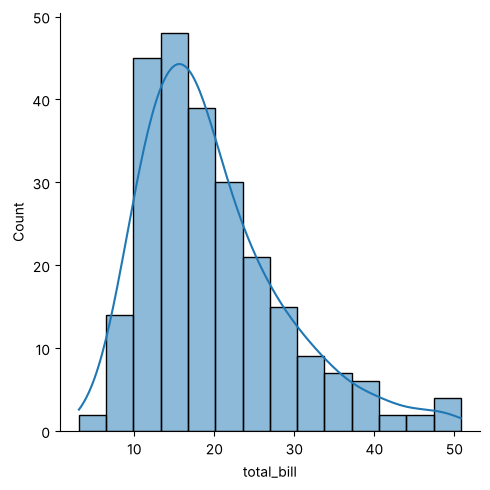

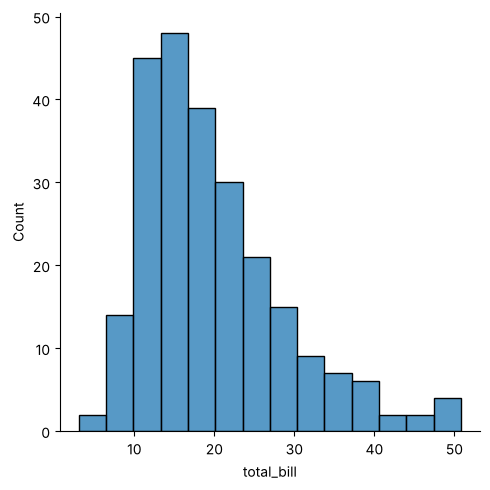

In [89]:
sns.displot(tips.total_bill, kde=True)
sns.displot(tips.total_bill, kde=False)
plt.show()

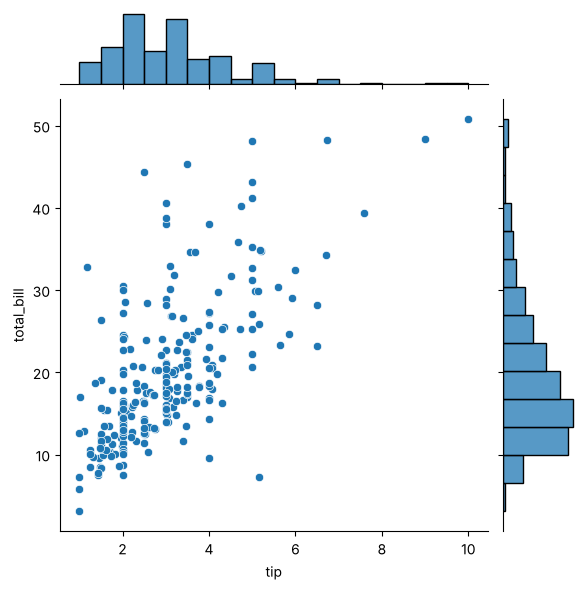

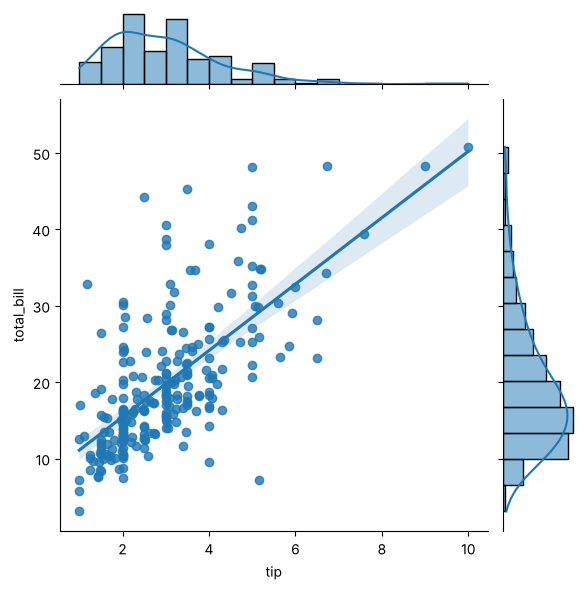

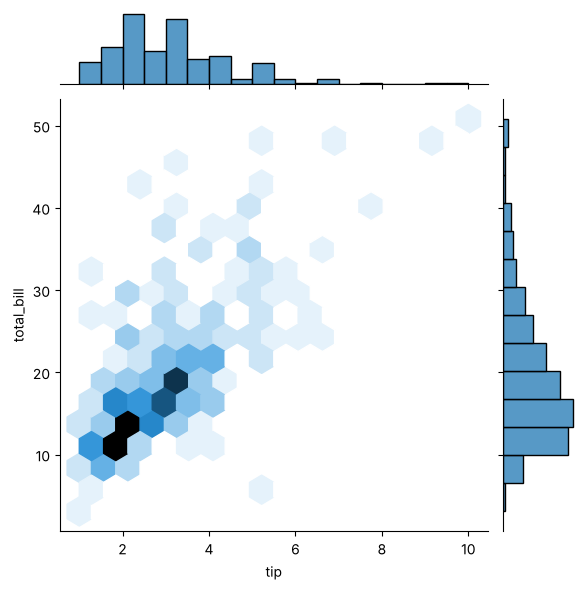

In [90]:
sns.jointplot(x=tips.tip, y=tips.total_bill)
sns.jointplot(x=tips.tip, y=tips.total_bill, kind="reg")
sns.jointplot(x=tips.tip, y=tips.total_bill, kind="hex")
plt.show()

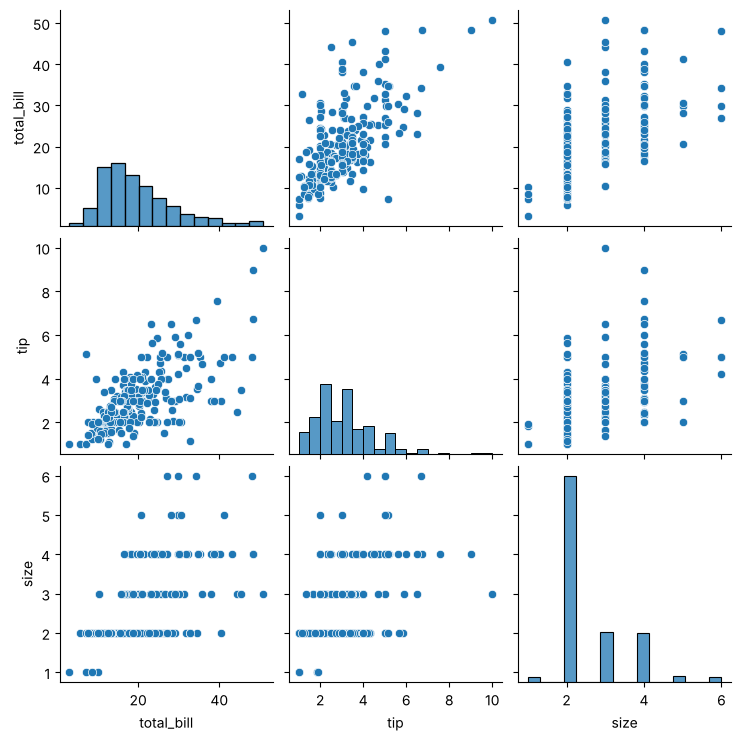

In [91]:
sns.pairplot(tips)
plt.show()

time
Dinner    176
Lunch      68
Name: count, dtype: int64


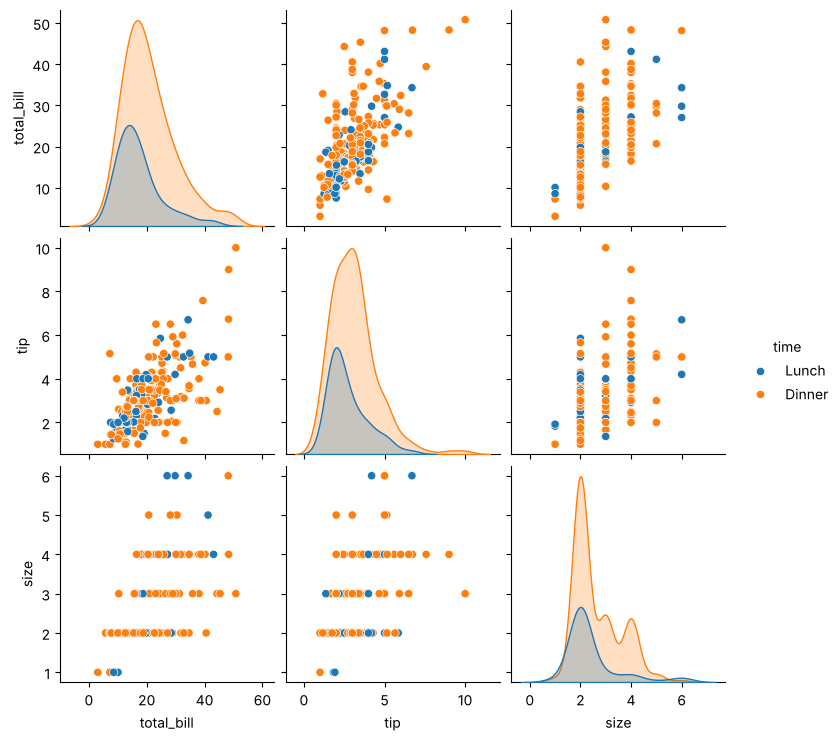

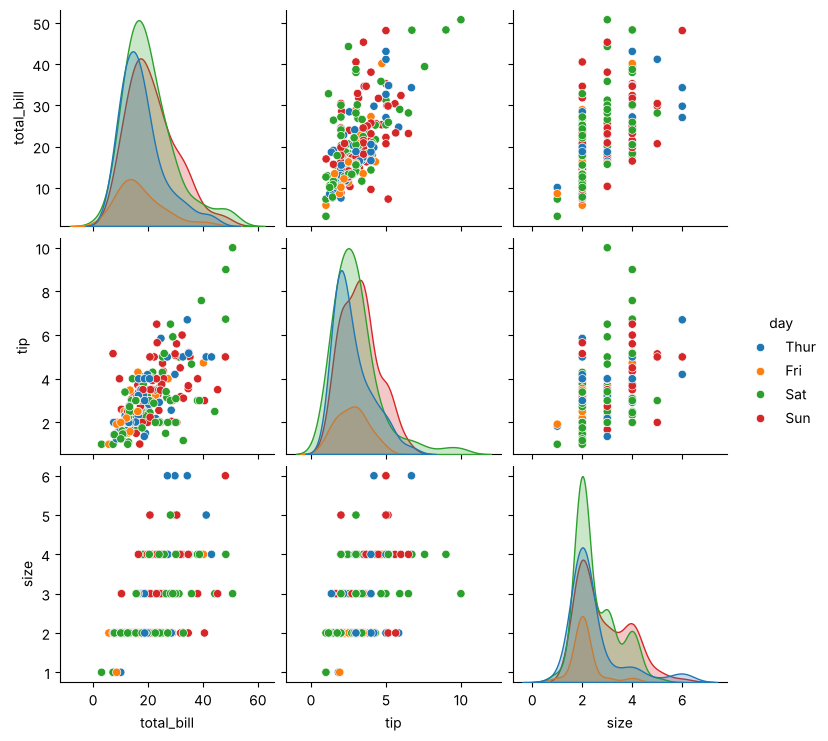

In [92]:
print(tips.time.value_counts())
sns.pairplot(tips, hue='time')
plt.show()
sns.pairplot(tips, hue='day')
plt.show()

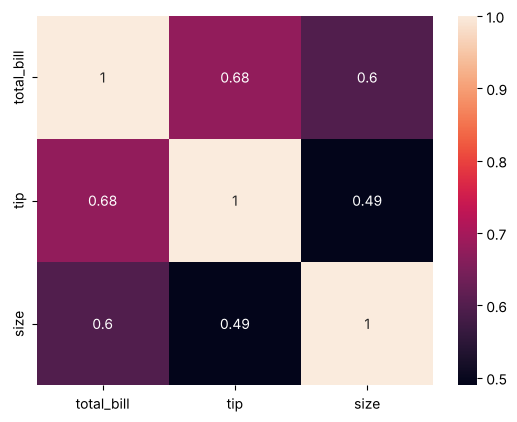

In [93]:
sns.heatmap(tips.corr(numeric_only=True), annot=True)
plt.show()

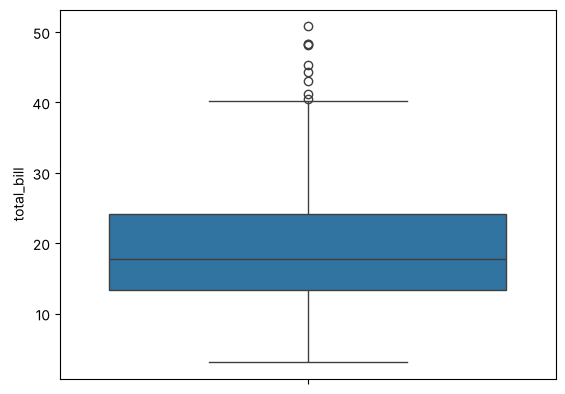

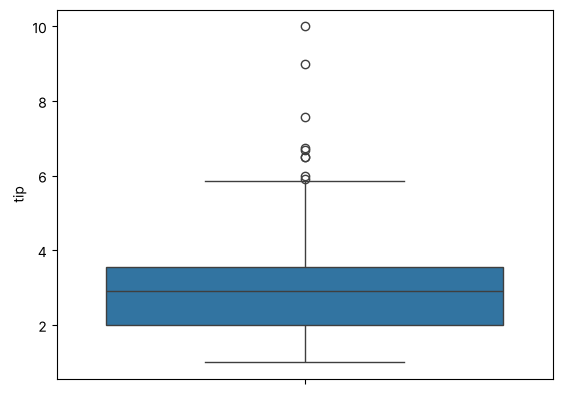

In [94]:
sns.boxplot(y=tips.total_bill)
plt.show()
sns.boxplot(y=tips.tip)
plt.show()

#### Qualitative (categorical) analysis

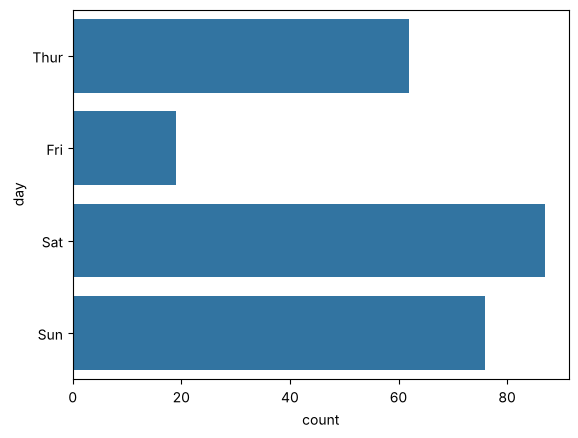

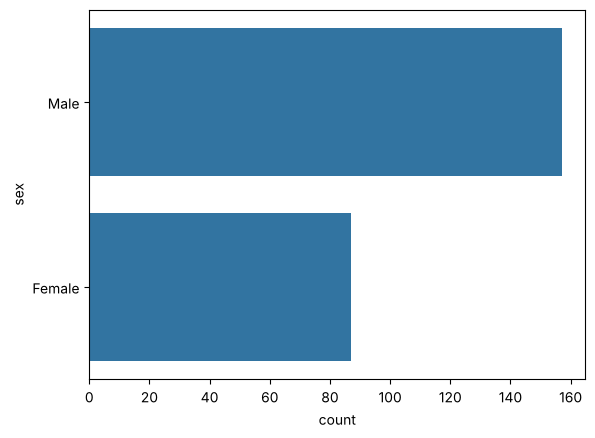

In [95]:
sns.countplot(y=tips.day)
plt.show()
sns.countplot(y=tips.sex)
plt.show()

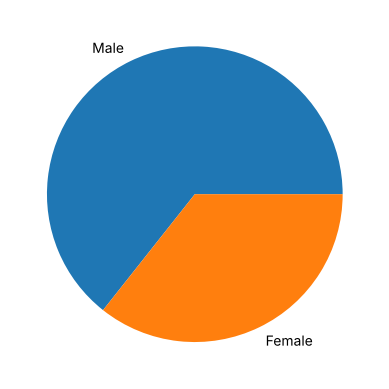

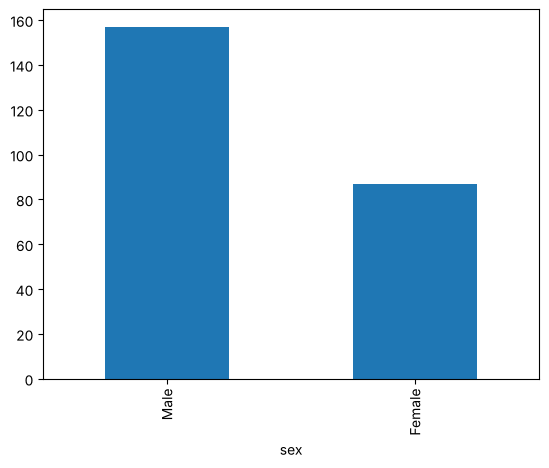

In [96]:
tips.sex.value_counts().plot(kind='pie')
plt.show()
tips.sex.value_counts().plot(kind='bar')
plt.show()

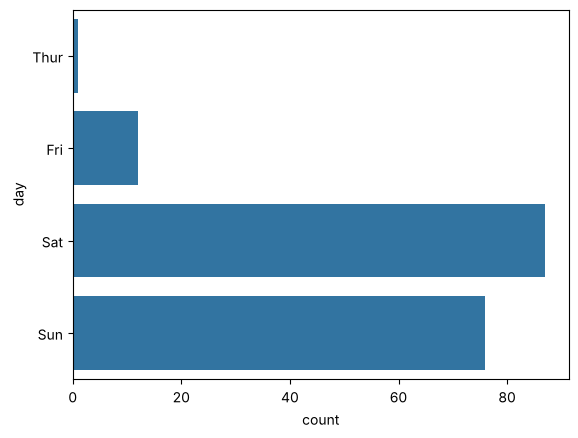

In [97]:
sns.countplot(y=tips[tips.time == 'Dinner']['day'])
plt.show()

---
## Experiment 17: Linear Regression

**Aim:** To understand Linear Regression on a given data set (Salary vs Years of Experience).

**Data:** the 30-row `Salary_data.csv` (Years of Experience vs Salary) is created below.

In [98]:
import pandas as pd

years = [1.1,1.3,1.5,2.0,2.2,2.9,3.0,3.2,3.2,3.7,3.9,4.0,4.0,4.1,4.5,4.9,5.1,5.3,5.9,6.0,6.8,7.1,7.9,8.2,8.7,9.0,9.5,9.6,10.3,10.5]
salary = [39343,46205,37731,43525,39891,56642,60150,54445,64445,57189,63218,55794,56957,57081,61111,67938,66029,83088,81363,93940,91738,98273,101302,113812,109431,105582,116969,112635,122391,121872]
pd.DataFrame({'YearsExperience': years, 'Salary': salary}).to_csv('Salary_data.csv', index=False)

In [99]:
import numpy as np
import pandas as pd

df = pd.read_csv('Salary_data.csv')
df

,YearsExperience,Salary
0,1.1,39343
1,1.3,46205
2,1.5,37731
3,2.0,43525
4,2.2,39891
5,2.9,56642
6,3.0,60150
7,3.2,54445
8,3.2,64445
9,3.7,57189


In [100]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 612.0 bytes


In [101]:
df.dropna(inplace=True)
df.describe()

,YearsExperience,Salary
count,30.000000,30.000000
mean,5.313333,76003.000000
std,2.837888,27414.429785
min,1.100000,37731.000000
25%,3.200000,56720.750000
50%,4.700000,65237.000000
75%,7.700000,100544.750000
max,10.500000,122391.000000


In [102]:
features = df.iloc[:, [0]].values
label = df.iloc[:, [1]].values

from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(features, label, test_size=0.2, random_state=23)

from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[9281.31]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[27166.74]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[14.7]


In [103]:
print("Train score (R2):", model.score(x_train, y_train))
print("Test score  (R2):", model.score(x_test, y_test))
print("Coefficient :", model.coef_)
print("Intercept   :", model.intercept_)

Train score (R2): 0.9603182547438908
Test score  (R2): 0.9184170849214232
Coefficient : [[9281.30847068]]
Intercept   : [27166.73682891]


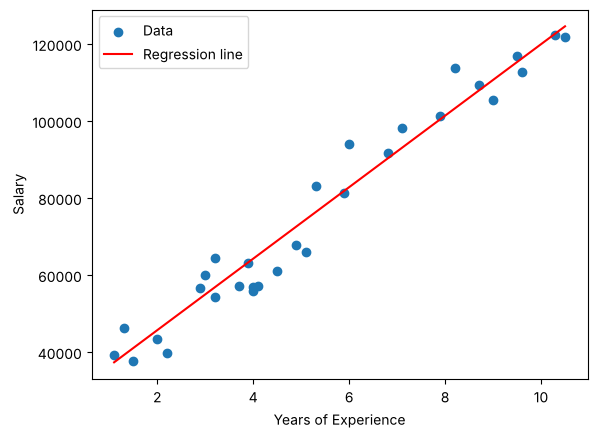

In [104]:
import matplotlib.pyplot as plt
plt.scatter(features, label, label='Data')
plt.plot(features, model.predict(features), color='red', label='Regression line')
plt.xlabel('Years of Experience'); plt.ylabel('Salary'); plt.legend()
plt.show()

**Save the model and predict a salary** (you will be asked to type the years of experience).

In [105]:
import pickle
pickle.dump(model, open('SalaryPred.model', 'wb'))
model = pickle.load(open('SalaryPred.model', 'rb'))

yr_of_exp = float(input("Enter Years of Experience: "))
yr_of_exp_NP = np.array([[yr_of_exp]])
Salary = model.predict(yr_of_exp_NP)
print("Estimated Salary for {} years of experience is {}: ".format(yr_of_exp, Salary))

Estimated Salary for 44.0 years of experience is [[435544.30953887]]: 


---
## Experiment 18: K-Nearest Neighbours (KNN) Algorithm

**Aim:** To understand the KNN classification algorithm on the Iris data set.

**Data:** `Iris.csv` (150 rows, columns sepal.length, sepal.width, petal.length, petal.width, variety) is built from scikit-learn's Iris data unless you have uploaded your own copy.

In [106]:
import os
import pandas as pd
from sklearn.datasets import load_iris

if not os.path.exists('Iris.csv'):
    iris = load_iris(as_frame=True)
    d = iris.frame.copy()
    d.columns = ['sepal.length', 'sepal.width', 'petal.length', 'petal.width', 'target']
    d['variety'] = d['target'].map({0: 'Setosa', 1: 'Versicolor', 2: 'Virginica'})
    d.drop(columns='target').to_csv('Iris.csv', index=False)
    print("Created Iris.csv")

Created Iris.csv


In [107]:
import numpy as np
import pandas as pd

df = pd.read_csv('Iris.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal.length  150 non-null    float64
 1   sepal.width   150 non-null    float64
 2   petal.length  150 non-null    float64
 3   petal.width   150 non-null    float64
 4   variety       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [108]:
print(df.variety.value_counts())
df.head()

variety
Setosa        50
Versicolor    50
Virginica     50
Name: count, dtype: int64


,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


In [109]:
features = df.iloc[:, :-1].values
label = df.iloc[:, 4].values

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

xtrain, xtest, ytrain, ytest = train_test_split(features, label, test_size=.2, random_state=1)
model_KNN = KNeighborsClassifier(n_neighbors=5)
model_KNN.fit(xtrain, ytrain)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](3,)","['Setosa','Versicolor','Virginica']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [110]:
print("Train accuracy:", model_KNN.score(xtrain, ytrain))
print("Test accuracy :", model_KNN.score(xtest, ytest))

Train accuracy: 0.9583333333333334
Test accuracy : 1.0


In [111]:
from sklearn.metrics import confusion_matrix
confusion_matrix(label, model_KNN.predict(features))

array([[50,  0,  0],
       [ 0, 47,  3],
       [ 0,  2, 48]])

In [112]:
from sklearn.metrics import classification_report
print(classification_report(label, model_KNN.predict(features)))

              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        50
  Versicolor       0.96      0.94      0.95        50
   Virginica       0.94      0.96      0.95        50

    accuracy                           0.97       150
   macro avg       0.97      0.97      0.97       150
weighted avg       0.97      0.97      0.97       150



---
## Experiment 19: Logistic Regression

**Aim:** To understand the Logistic Regression algorithm on the Social Network Ads data set (will the user purchase?).

**Data:** if `Social_Network_Ads.csv` is not uploaded, a 400-row sample with the same columns (User ID, Gender, Age, EstimatedSalary, Purchased) is created. Upload the real file with the same name to use it instead.

In [113]:
import os
import numpy as np
import pandas as pd

if not os.path.exists('Social_Network_Ads.csv'):
    rng = np.random.default_rng(7)
    n = 400
    age = rng.integers(18, 60, n)
    salary = (rng.integers(15, 150, n) * 1000)
    score = 0.25 * (age - 38) + 0.00002 * (salary - 70000) + rng.normal(0, 1.2, n)
    purchased = np.zeros(n, dtype=int)
    purchased[np.argsort(score)[-143:]] = 1                      # 143 buyers, as in the original data
    pd.DataFrame({'User ID': rng.integers(15570000, 15820000, n),
                  'Gender': rng.choice(['Male', 'Female'], n),
                  'Age': age, 'EstimatedSalary': salary, 'Purchased': purchased}
                 ).to_csv('Social_Network_Ads.csv', index=False)
    print("Created sample Social_Network_Ads.csv")

Created sample Social_Network_Ads.csv


In [114]:
import numpy as np
import pandas as pd

df = pd.read_csv('Social_Network_Ads.csv')
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624038,Male,57,101000,1
1,15683234,Male,44,124000,1
2,15645452,Male,46,74000,0
3,15805694,Female,55,103000,1
4,15694397,Female,42,44000,0


In [115]:
features = df.iloc[:, [2, 3]].values   # Age, EstimatedSalary
label = df.iloc[:, 4].values           # Purchased
features[:5], label[:20]

(array([[    57, 101000],
        [    44, 124000],
        [    46,  74000],
        [    55, 103000],
        [    42,  44000]]),
 array([1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0]))

Search for a random_state where the test score is higher than the train score (the manual loops over 1…400):

In [116]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

results = []
for i in range(1, 401):
    x_train, x_test, y_train, y_test = train_test_split(features, label, test_size=0.2, random_state=i)
    model = LogisticRegression()
    model.fit(x_train, y_train)
    train_score = model.score(x_train, y_train)
    test_score = model.score(x_test, y_test)
    if test_score > train_score:
        results.append((test_score, train_score, i))

print("random states where Test > Train:", len(results))
best = max(results)
print("Best -> Test {:.4f}  Train {:.4f}  Random State {}".format(*best))

random states where Test > Train: 176
Best -> Test 0.9750  Train 0.8969  Random State 272


In [117]:
best_state = best[2]
x_train, x_test, y_train, y_test = train_test_split(features, label, test_size=0.2, random_state=best_state)
finalModel = LogisticRegression()
finalModel.fit(x_train, y_train)

print("Train accuracy:", finalModel.score(x_train, y_train))
print("Test accuracy :", finalModel.score(x_test, y_test))

Train accuracy: 0.896875
Test accuracy : 0.975


In [118]:
from sklearn.metrics import classification_report
print(classification_report(label, finalModel.predict(features)))

              precision    recall  f1-score   support

           0       0.93      0.94      0.93       257
           1       0.89      0.87      0.88       143

    accuracy                           0.91       400
   macro avg       0.91      0.90      0.90       400
weighted avg       0.91      0.91      0.91       400



---
## Experiment 20: K-Means Clustering

**Aim:** To understand the K-Means clustering algorithm on the Mall Customers data set.

**Data:** if `Mall_Customers.csv` is not uploaded, a 200-row sample with the same columns (CustomerID, Gender, Age, Annual Income (k$), Spending Score (1-100)) and five natural customer groups is created.

In [119]:
import os
import numpy as np
import pandas as pd

if not os.path.exists('Mall_Customers.csv'):
    rng = np.random.default_rng(3)
    centers = [(26, 20), (26, 79), (55, 50), (87, 18), (87, 82)]    # (income, spending score)
    sizes = [22, 22, 80, 38, 38]
    pts = np.vstack([rng.normal(c, 6, (s, 2)) for c, s in zip(centers, sizes)]).clip(15, 137).round().astype(int)
    pts[:, 1] = pts[:, 1].clip(1, 99)
    pts = pts[rng.permutation(len(pts))]
    pd.DataFrame({'CustomerID': range(1, 201),
                  'Gender': rng.choice(['Male', 'Female'], 200),
                  'Age': rng.integers(18, 70, 200),
                  'Annual Income (k$)': pts[:, 0],
                  'Spending Score (1-100)': pts[:, 1]}).to_csv('Mall_Customers.csv', index=False)
    print("Created sample Mall_Customers.csv")

Created sample Mall_Customers.csv


In [120]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

df = pd.read_csv('Mall_Customers.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [121]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,33,53,49
1,2,Male,25,26,29
2,3,Male,43,26,79
3,4,Female,49,86,99
4,5,Female,24,25,23


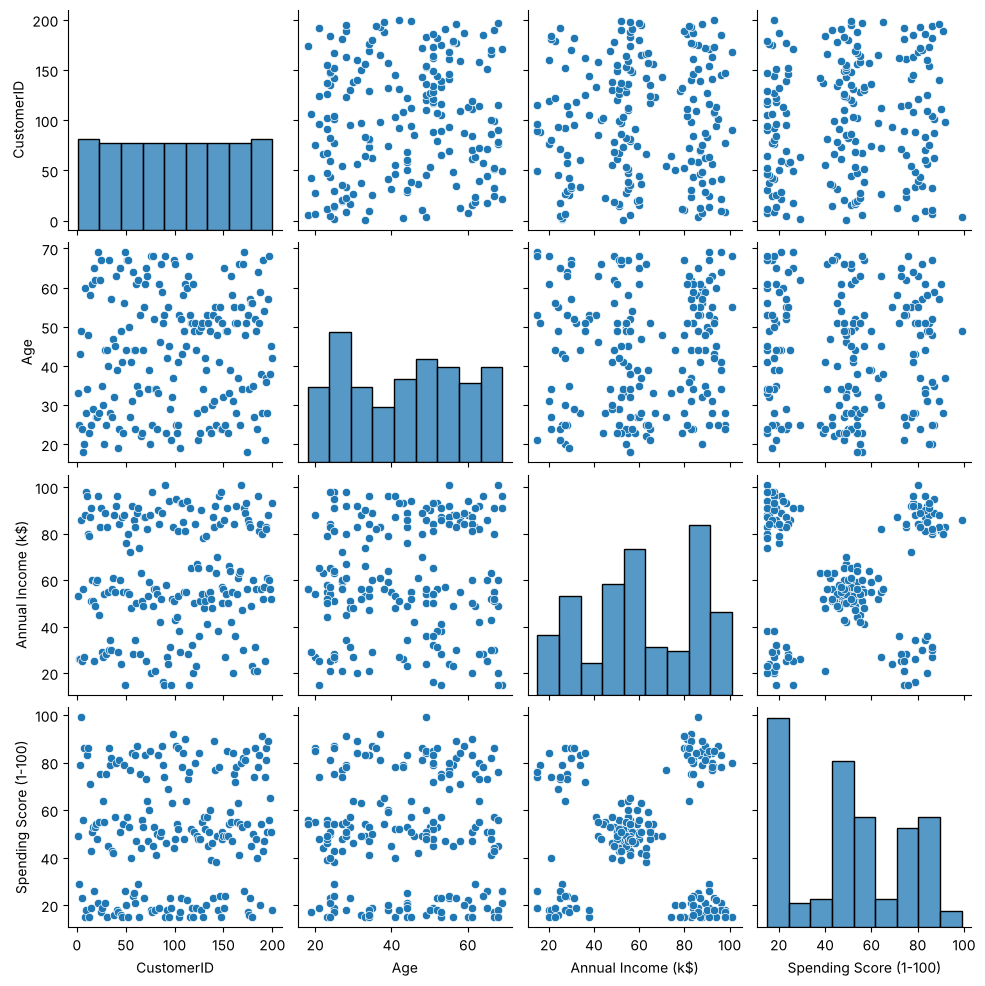

In [122]:
sns.pairplot(df)
plt.show()

#### Clustering on Annual Income and Spending Score (k = 5)

In [123]:
features = df.iloc[:, [3, 4]].values

from sklearn.cluster import KMeans
model = KMeans(n_clusters=5, n_init=10, random_state=0)
model.fit(features)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",5
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",0
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](5, 2)","[[54.7

In [124]:
Final = df.iloc[:, [3, 4]].copy()
Final['label'] = model.predict(features)
Final.head()

,Annual Income (k$),Spending Score (1-100),label
0,53,49,0
1,26,29,3
2,26,79,4
3,86,99,1
4,25,23,3


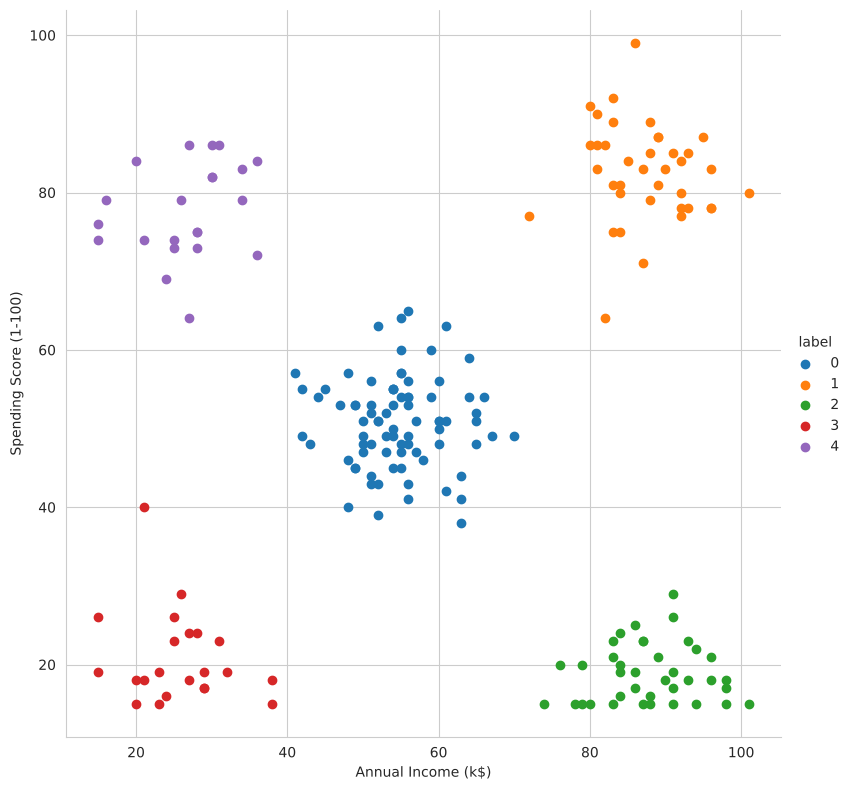

In [125]:
sns.set_style("whitegrid")
sns.FacetGrid(Final, hue="label", height=8) \
   .map(plt.scatter, "Annual Income (k$)", "Spending Score (1-100)") \
   .add_legend()
plt.show()

#### Elbow method – choosing the number of clusters (using Age, Income and Spending Score)

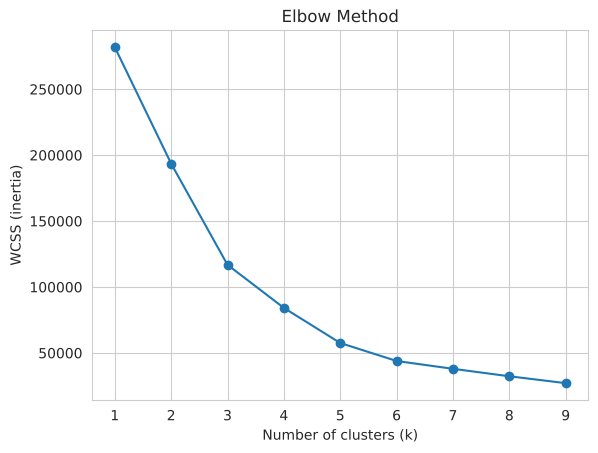

In [126]:
features_el = df.iloc[:, [2, 3, 4]].values

wcss = []
for i in range(1, 10):
    model = KMeans(n_clusters=i, n_init=10, random_state=0)
    model.fit(features_el)
    wcss.append(model.inertia_)

plt.plot(range(1, 10), wcss, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('WCSS (inertia)')
plt.title('Elbow Method')
plt.show()